# Passive Bayesian beamforming

**What do the snapshots identify, what does uncertainty add, and does it improve the decision?**

An eight-sensor array observes an interferer plus sensor noise. We first connect these observations to a subspace posterior, then examine tracking, the beamformer, uncertainty, unknown powers and changing spatial signatures. Each main figure answers one question. The appendix retains the earlier rank-three and real low-data studies under their original models.

This is the executed **paper profile**: 128 independent validation trajectories and 256 independent test trajectories for the principal decision comparisons, with $q=1$, $s\in\{1,0.2\}$ and $N\in\{1,2,4,8,16,32,64\}$. The parameter-inference and expensive reference cohorts are smaller and explicitly identified below. Displayed trajectories and reporting times were selected before test generation. Numerical failures and unfavorable comparisons remain in the tables.

In [1]:
from pathlib import Path
import hashlib, json
import numpy as np
import pandas as pd
from IPython.display import Image, display, Markdown
ROOT = Path.cwd()
if not (ROOT / 'lib').is_dir():
    ROOT = ROOT.parent
from lib.plotting import plt
from lib.beamforming_visuals import load_unified
from lib.beamforming_history import verify_historical
D = load_unified(ROOT, 'paper', verify=True)
F = D['base'] / 'figures'
FIGURES = json.loads((F / 'manifest.json').read_text())
assert plt.rcParams['text.usetex'] is True
assert plt.rcParams['figure.dpi'] == plt.rcParams['savefig.dpi'] == 200
for name, expected in FIGURES['sources'].items():
    assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == expected
for name, expected in FIGURES['input_manifests'].items():
    assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == expected
SUMMARY = json.loads((D['base'].parent / 'summary_manifest.json').read_text())
assert SUMMARY['profile'] == 'paper' and SUMMARY['paper_evidence'] is True
for mapping in ('verified_input_hashes', 'source_hashes', 'outputs'):
    for name, expected in SUMMARY[mapping].items():
        assert hashlib.sha256((ROOT / name).read_bytes()).hexdigest() == expected

def show(name):
    filename = name + '.png'
    path = F / filename
    assert hashlib.sha256(path.read_bytes()).hexdigest() == FIGURES['files'][filename]
    display(Image(filename=str(path), width=1400))
    caption = FIGURES.get('captions', {}).get(name)
    if caption:
        display(Markdown(caption))

print('Verified paper tables, numerical sources, validation gate and figure sources.')

Verified paper tables, numerical sources, validation gate and figure sources.


## 1. What is observed?

The training snapshot is $u_t=h_tz_t+e_t$, with $\|h_t\|=1$, $z_t\sim\mathcal{CN}(0,q)$ and $e_t\sim\mathcal{CN}(0,sI)$. After integrating out the unknown coefficient, $u_t\mid P_t\sim\mathcal{CN}(0,sI+qP_t)$, where $P_t=h_th_t^H$. **Only $u_t$ enters the estimator.** The hidden signature and coefficients generate data and evaluate error; they are not known training inputs. The desired signature $a$ enters only when choosing a weight satisfying $w^Ha=1$.

The setup shows a half-wavelength ULA, observed snapshot magnitudes and the population covariance spectrum. Its dominant eigenvalue is $s+q$; the remaining seven are $s$. The physical example uses desired arrival $-20^\circ$ and stationary interferer arrival $20^\circ$. Internally, angles are radians. A Haar-distributed stationary complex line is the matched statistical control. A moving ULA and an invariant stochastic spatial-signature process are two different motion laws.

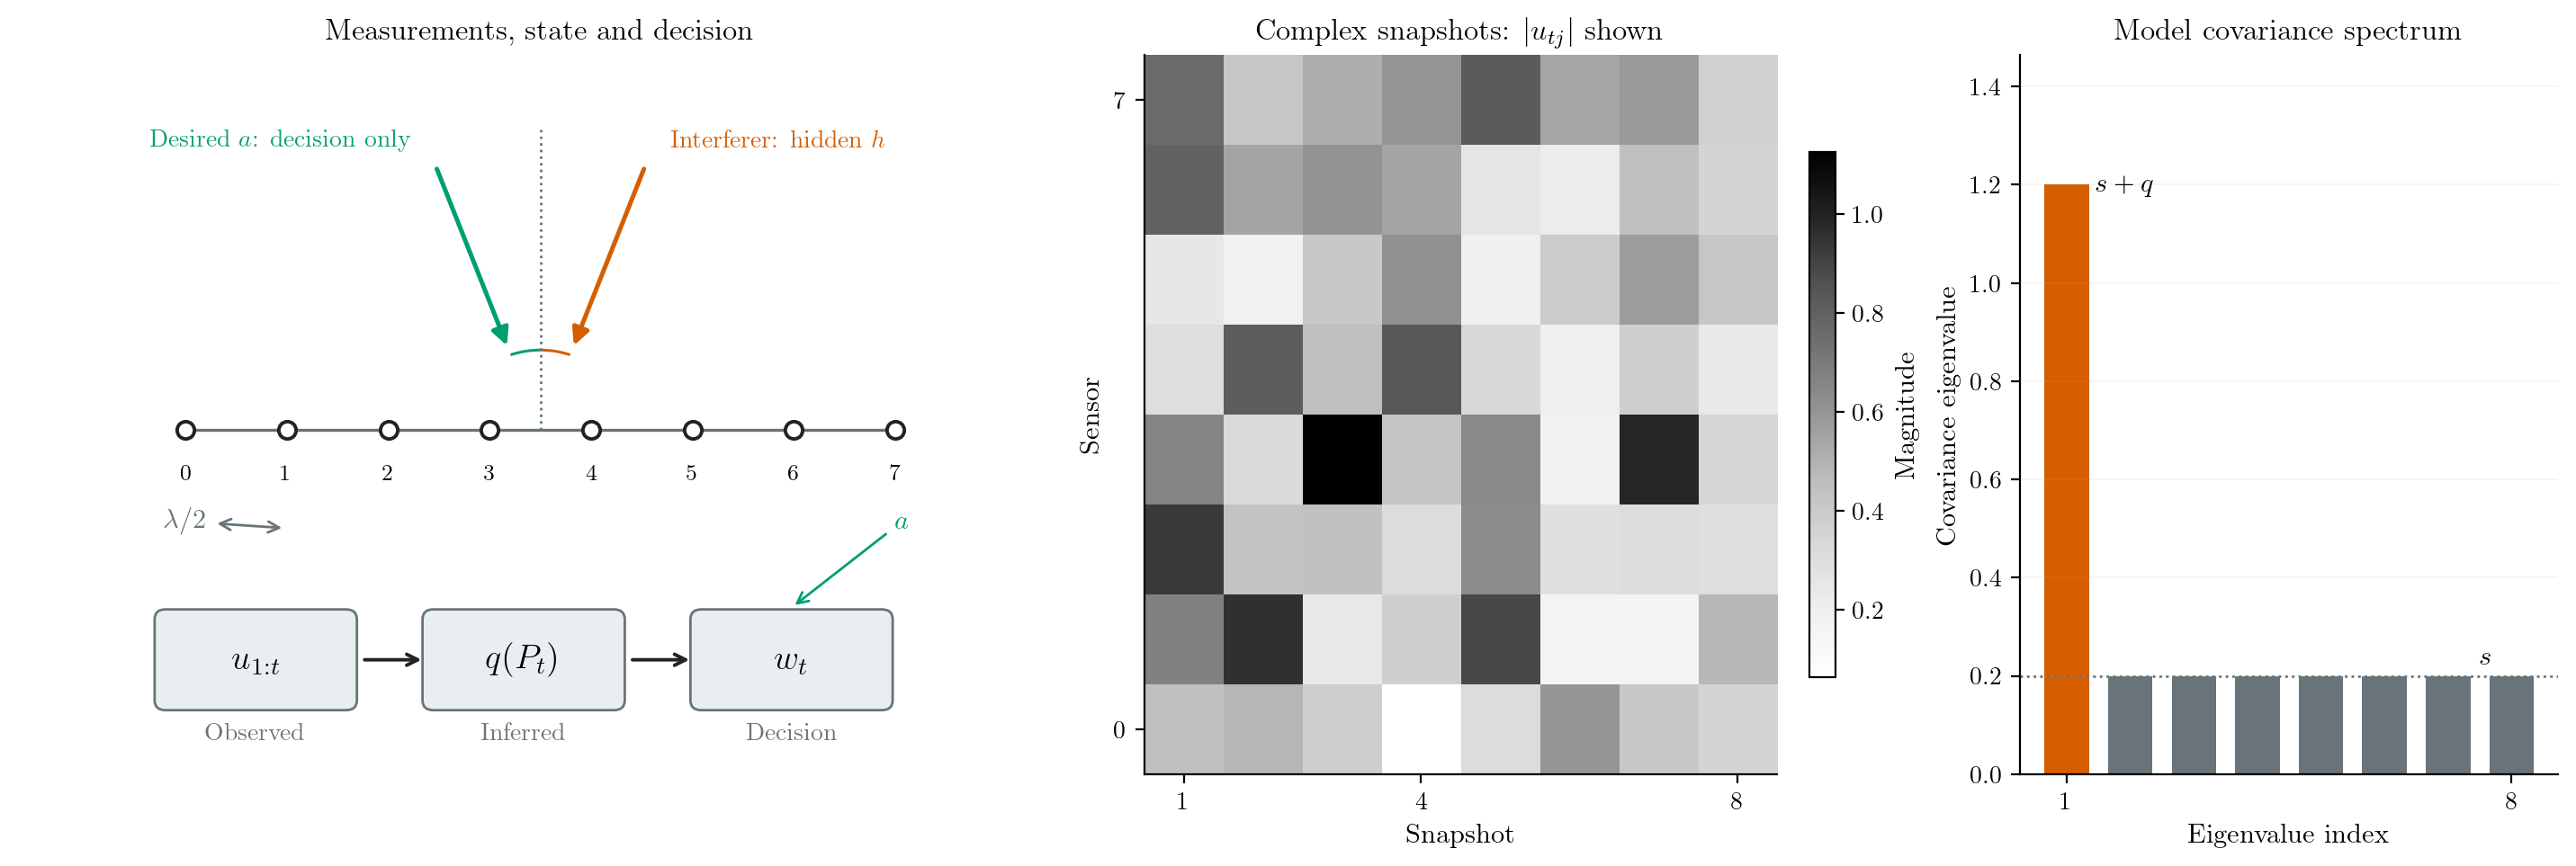

Eight half-wavelength-spaced sensors observe zero-mean complex snapshots. The hidden spatial line and its posterior are inferred from passive covariance information; the desired steering vector enters only the beamforming decision.

In [2]:
show('01_setup')

## 2. How do snapshots become information?

For known powers, the likelihood correction is $B_t=q\,u_tu_t^H/[s(s+q)]$ and the trace-zero Bingham parameter is updated once per snapshot. There is no real-Gaussian factor $1/2$. Under a uniform prior and the same weights and transports, the posterior mode is exactly weighted covariance PCA. This equivalence is checked against a separately accumulated scatter matrix.

In real coordinates $[\operatorname{Re}Z,\operatorname{Im}Z]$ of a complex Grassmann tangent, one snapshot has Fisher information $\mathcal I_0 I$, where $\mathcal I_0=2q^2/[s(s+q)]$. The first two panels compare independent Gaussian score calculations and expected-likelihood finite differences with this isotropic formula. Small matrix deviations are Monte Carlo error, not population anisotropy.

The third panel pulls the same information back to arrival angle: $\mathcal I_{\theta\theta}=N\mathcal I_0\pi^2\cos^2\theta(n^2-1)/12$, in radian coordinates. Angle information falls near endfire because the steering curve slows there. The ambient posterior is a distribution over complex lines; it is not an exact posterior restricted to one arrival angle.

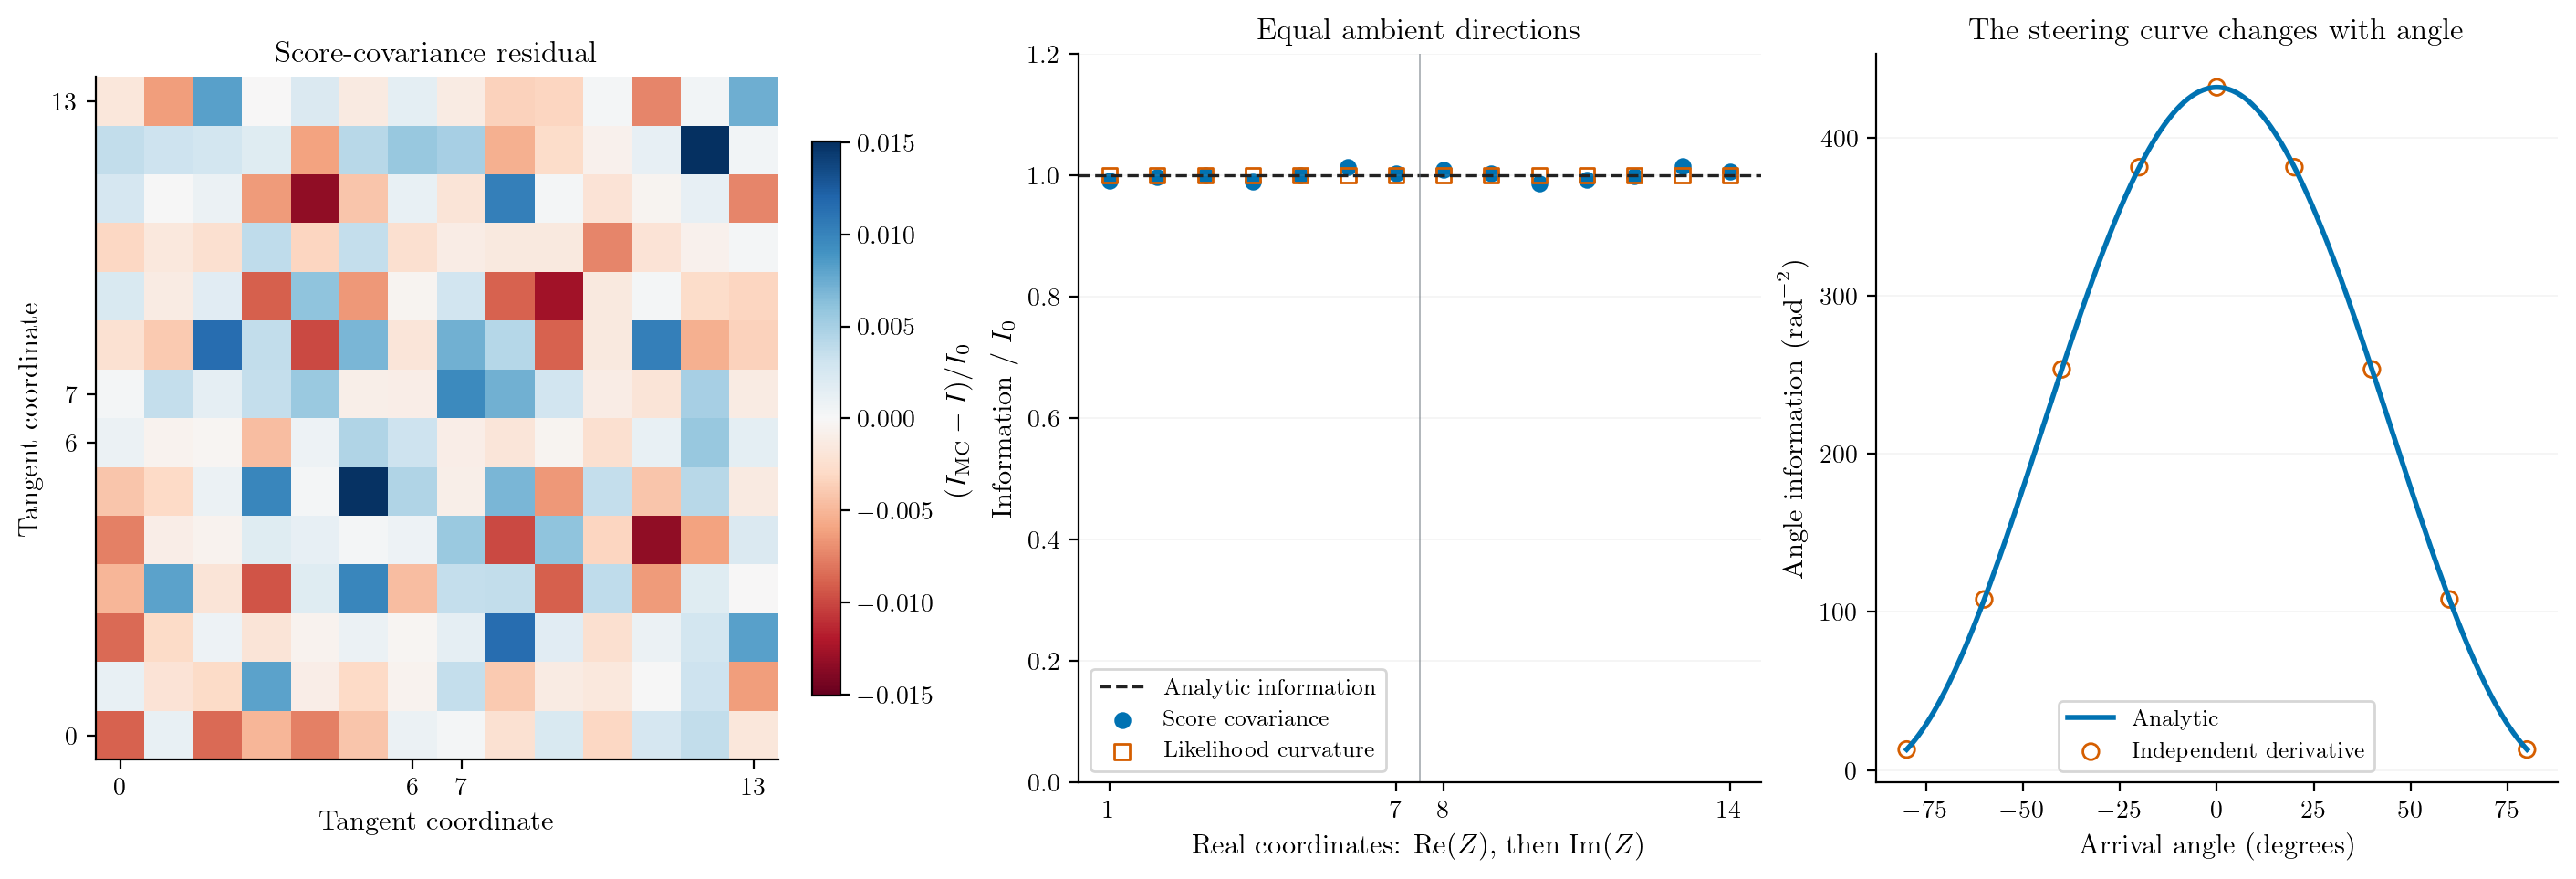

One-snapshot Fisher information is isotropic in the 14 real native-complex tangent coordinates. Small score-covariance residuals are Monte Carlo fluctuations, not population anisotropy. Physical arrival-angle information is a separate pullback along the ULA steering curve, in inverse radians squared.

In [3]:
show('02_information')
assert D['decisions']['metrics'].pca_projector_error.max() < 1e-7

## 3. How does motion compete with retained data?

The moving interferer follows $\theta_t=20^\circ+12^\circ\sin(2\pi(t-1)/128)$, while the practical transport is $G_t=I$. Forgetting is selected on independent validation trajectories. No true rotation is supplied to the tracker. Principal-angle error measures subspace error, rather than error in the physical arrival coordinate.

For deterministic weights and motion, fixed known powers and a uniform initial prior, the passive covariance certificate separates a noise allowance $\eta_t$ and a truth-dependent drift term $d_t^{\rm cov}$. With $\varepsilon_t=\eta_t+d_t^{\rm cov}<q/2$, the modal chordal error is at most $\varepsilon_t/(q-\varepsilon_t)$. Invalid conditions stay invalid. The drift term is available only for evaluation. $N_{\rm eff}=1/\sum\alpha_j^2$ describes retained weights; it is not automatically the Fisher information of a discounted posterior.

The practical short-horizon certificate is conservative. A separate stationary cohort with $n=4$, $s=0.2$, $N=4096$ makes it nonvacuous: $\eta=0.2570$ and bound $0.3459$. The fixed reporting-time comparisons use independent observation streams. They are pointwise guarantees, not one simultaneous event over the whole time curve. The same modal event controls every unit-direction covariance scan error by $q\,d_c$; it does not certify posterior-mean coverage.

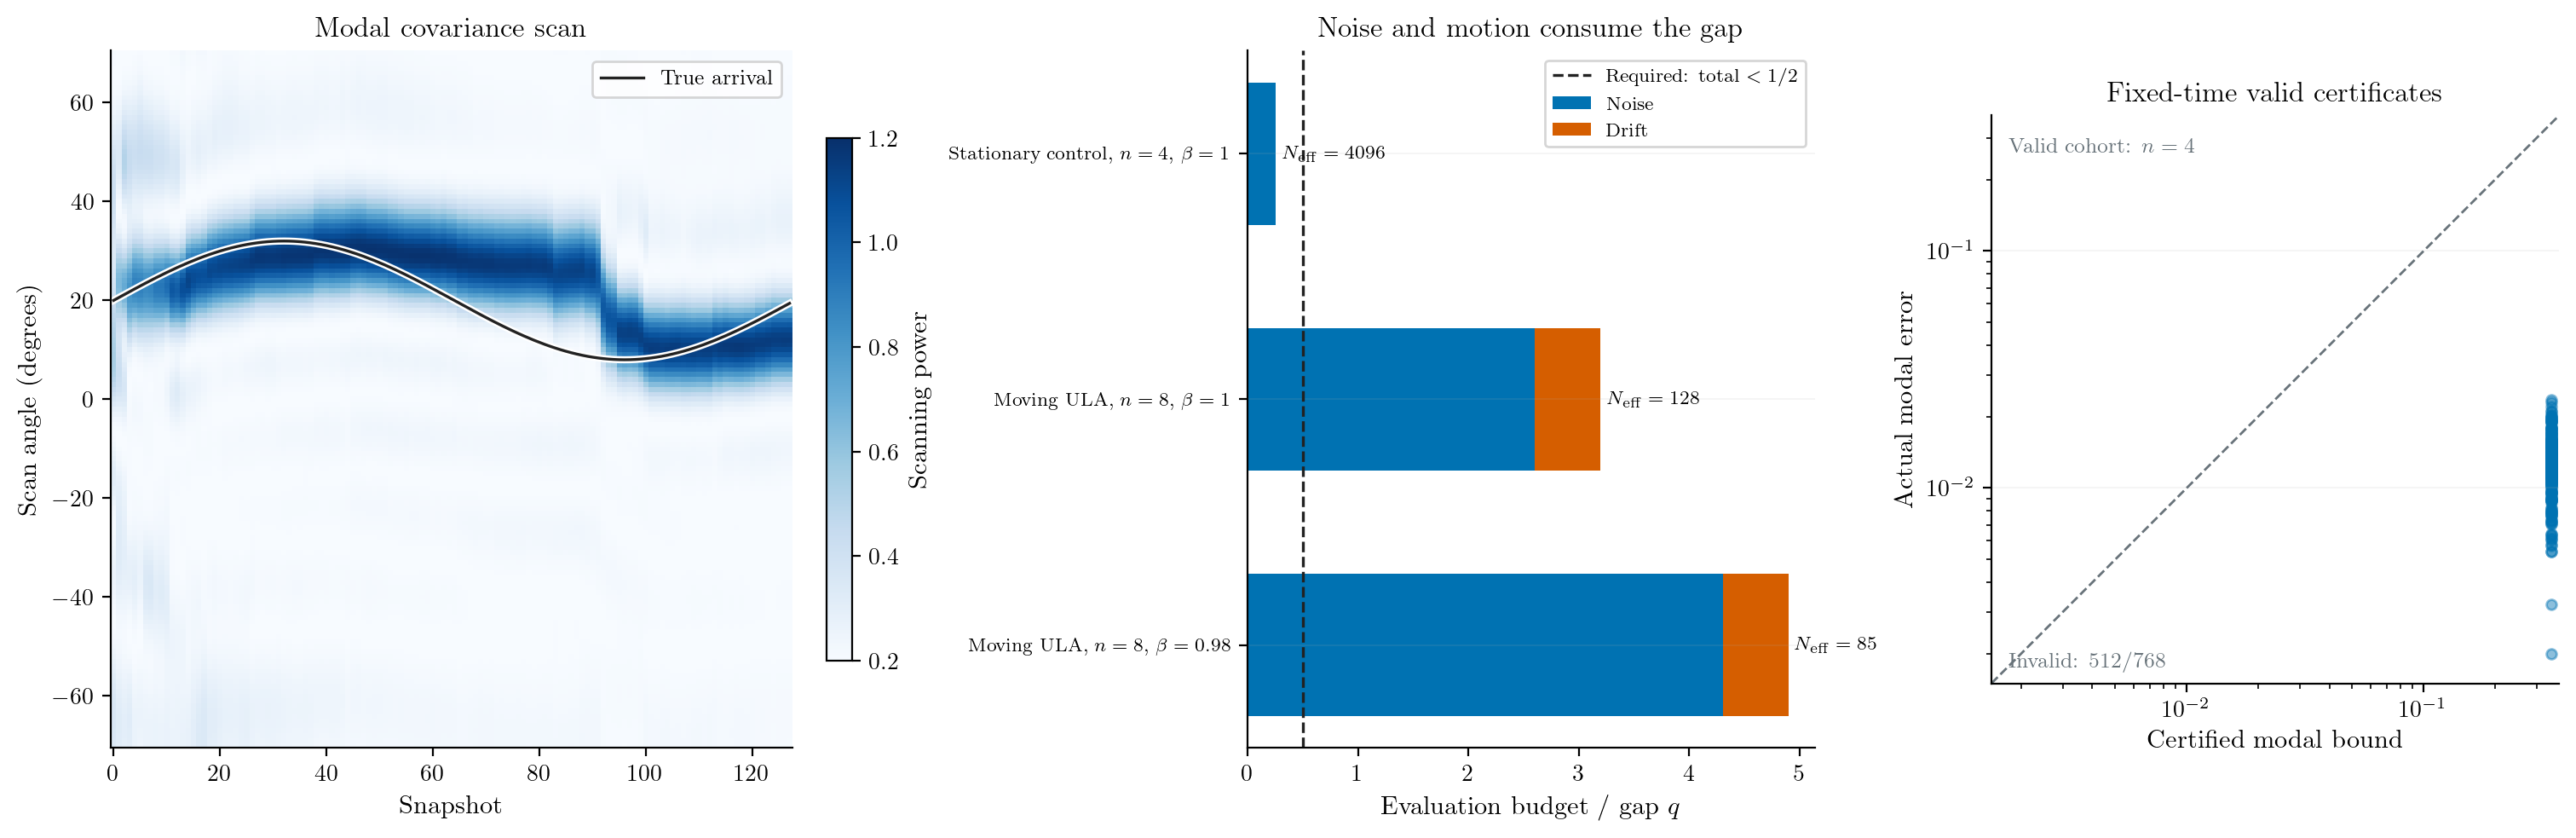

The physical moving-ULA record is preassigned trial zero at s=0.2. The scan uses modal covariance, not the actual beamforming weights. Noise and truth-dependent drift budgets are evaluated at predeclared fixed times; drift is unavailable to the estimator. Only valid certificates are compared with actual modal error; the valid long stationary cohort has n=4.

In [4]:
show('03_tracking')

## 4. Does the posterior change the beamforming decision?

The posterior-mean beamformer uses $\bar R=sI+qM$, $M=\mathbb E[P\mid U]$, and $w_\star=\bar R^{-1}a/(a^H\bar R^{-1}a)$. For every feasible alternative, its conditional expected-power excess is exactly $(w-w_\star)^H\bar R(w-w_\star)\geq0$. This checks a Bayes decision identity. Actual $w^HR_{\rm true}w$ and independent held-out snapshot power answer a different question and can favor a competitor.

The mode uses a single projector. The **isotropized mean** keeps its mode and mean squared chordal distance but removes directional structure from $M$: $M_{\rm iso}=\rho\widehat P+(1-\rho)I/n$, with $\rho$ determined from $M$, not test truth. The regularized-PCA comparator selects one scalar on validation. Loaded covariance searches a broad loading grid; moving methods also select forgetting independently. Stationary families use the declared $\beta=1$. GROUSE and independently tuned weighted PCA remain in the complete supplementary comparison.

A single snapshot has only two spectral levels, so $M=M_{\rm iso}$ exactly. Improvements over the mode at $N=1$ demonstrate uncertainty regularization, not directional anisotropy. At larger $N$, the paired comparisons retain gains, ties and losses. Confidence intervals use independent trajectories; all methods share their held-out snapshots. Held-out replicates are drawn at the current covariance, rather than being mislabeled future points on a moving path. Lower output power is better; none of these identities claims optimal expected SINR.

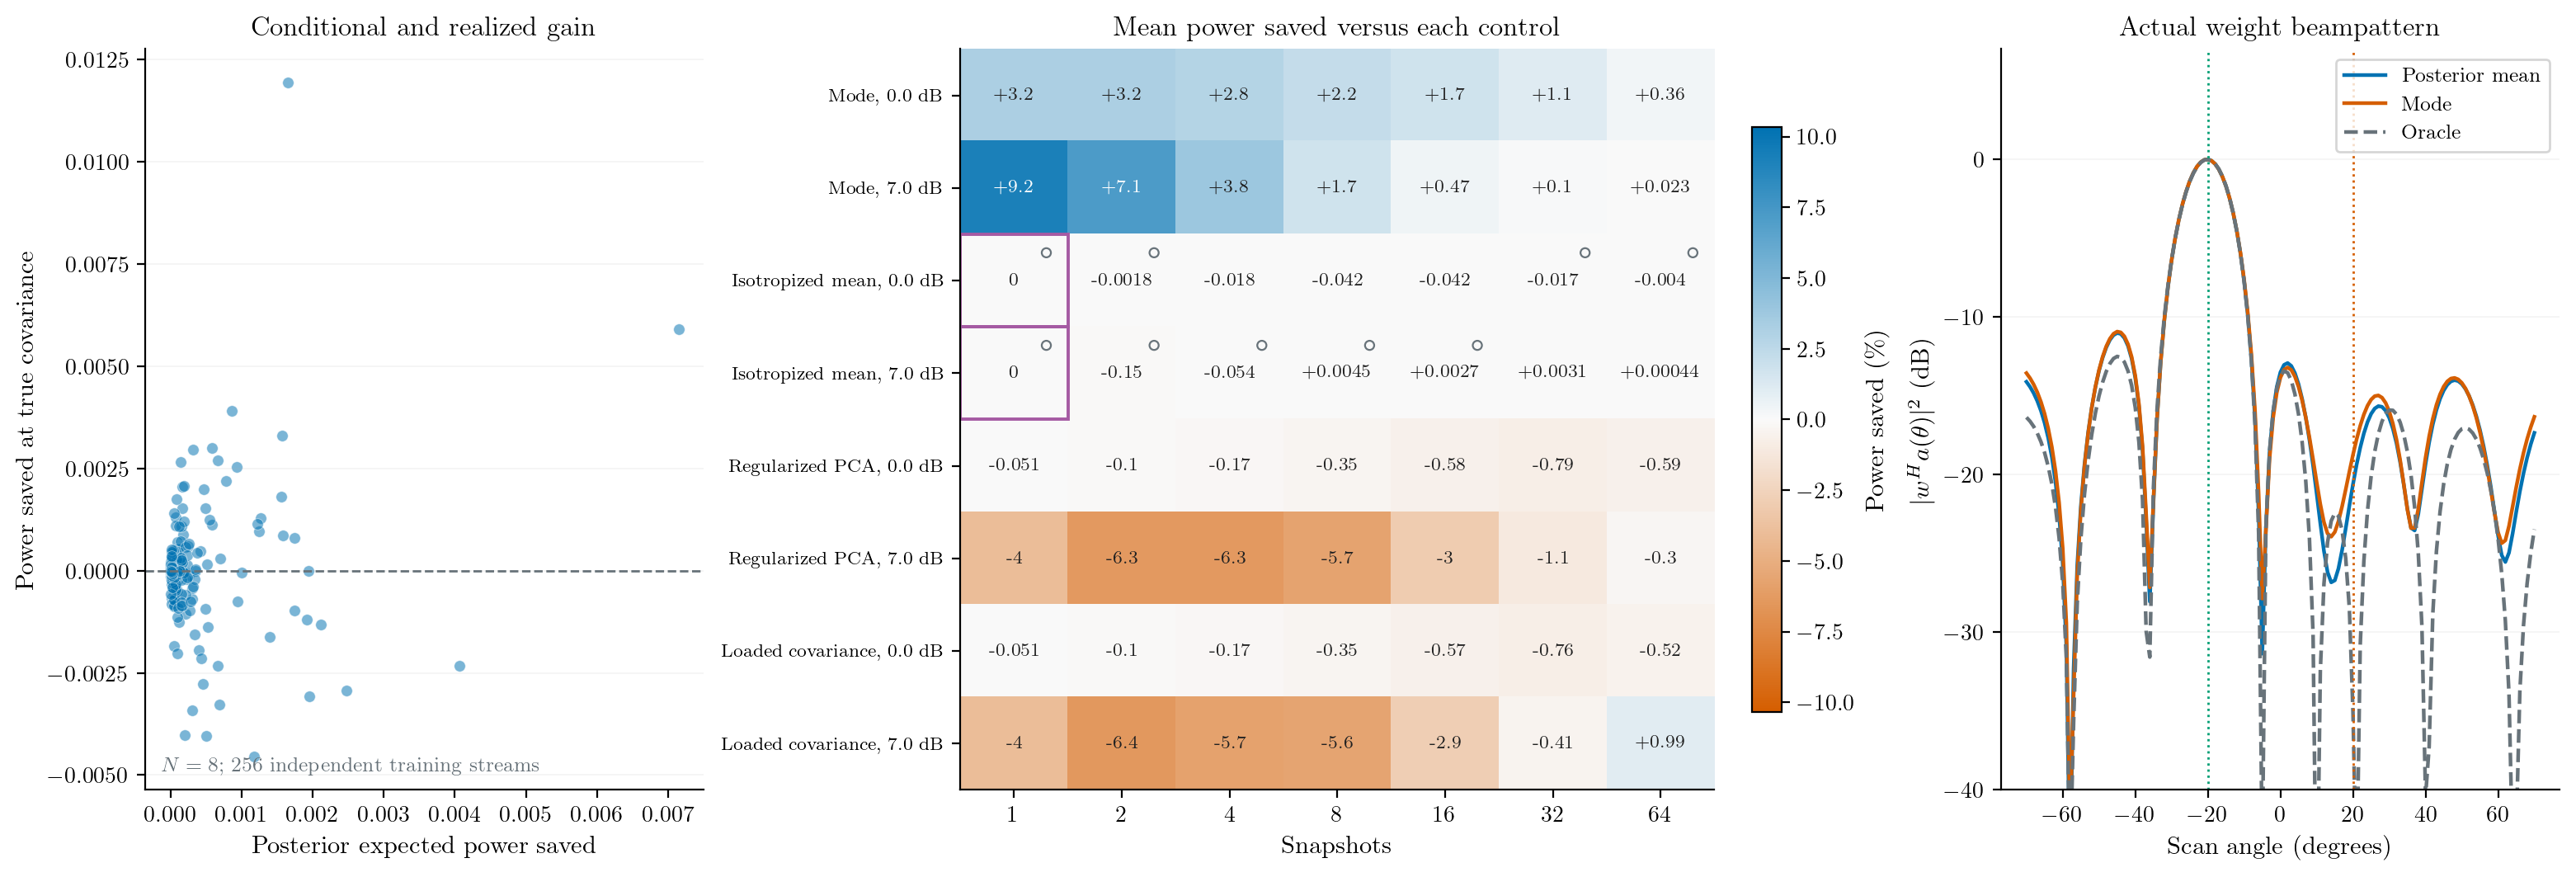

Each scatter point is an independent training stream at N=8. Posterior expected-power optimality does not imply a win at every true covariance. The complete horizon/noise map retains losses; open circles mark paired pointwise 95% intervals containing zero. Purple boxes mark exact one-snapshot isotropization ties. The final panel is the actual weight beampattern, not covariance scanning power.

In [5]:
show('04_decisions')
shape = D['decisions']['shape']
assert shape.loc[shape.t.eq(1), 'anisotropy'].max() < 1e-7
assert D['decisions']['metrics'].optimality_identity_error.max() < 1e-7

## 5. What do the uncertainty bands mean?

For the same preassigned stationary ULA trajectory, the blue bands are central **pointwise scalar** 50% and 95% posterior intervals for covariance scanning power $s+q\,a(\theta)^HPa(\theta)$. The state-region envelope instead takes extrema over one nominal 95% state HPD region. State inclusion implies enclosure of the truth at every evaluated angle. A scalar interval and a common state-region envelope have different meanings and widths. Neither is the weight beampattern $|w^Ha(\theta)|^2$.

There is a useful stationary passive coverage specialization. Known fixed powers, a uniform prior, $\beta=1$, unitary equivariance and an **exact-mass equivariant state region** imply 95% frequentist state coverage at every fixed state by transitivity and prior averaging. This also implies at least 95% enclosure by its common-state scan envelope. The finite sampling implementation checks achieved mass independently; it approximates that ideal region. The dedicated fixed-state cohort tests this claim at $e_1$ and at a $20^\circ$ ULA line.

This argument does not give arbitrary scalar equal-tail intervals 95% fixed-state coverage. At the exact interferer direction, the true power equals the support maximum $s+q$: every finite continuous posterior equal-tail interval excludes that endpoint. Thus scalar undercoverage at that query is possible even in the correctly specified stationary model. Moving truth, forgetting, learned parameters and moment-projected prediction also lie outside the stated state-coverage specialization. Coverage is shown alongside width/score and numerical precision, rather than as a stand-alone success metric.

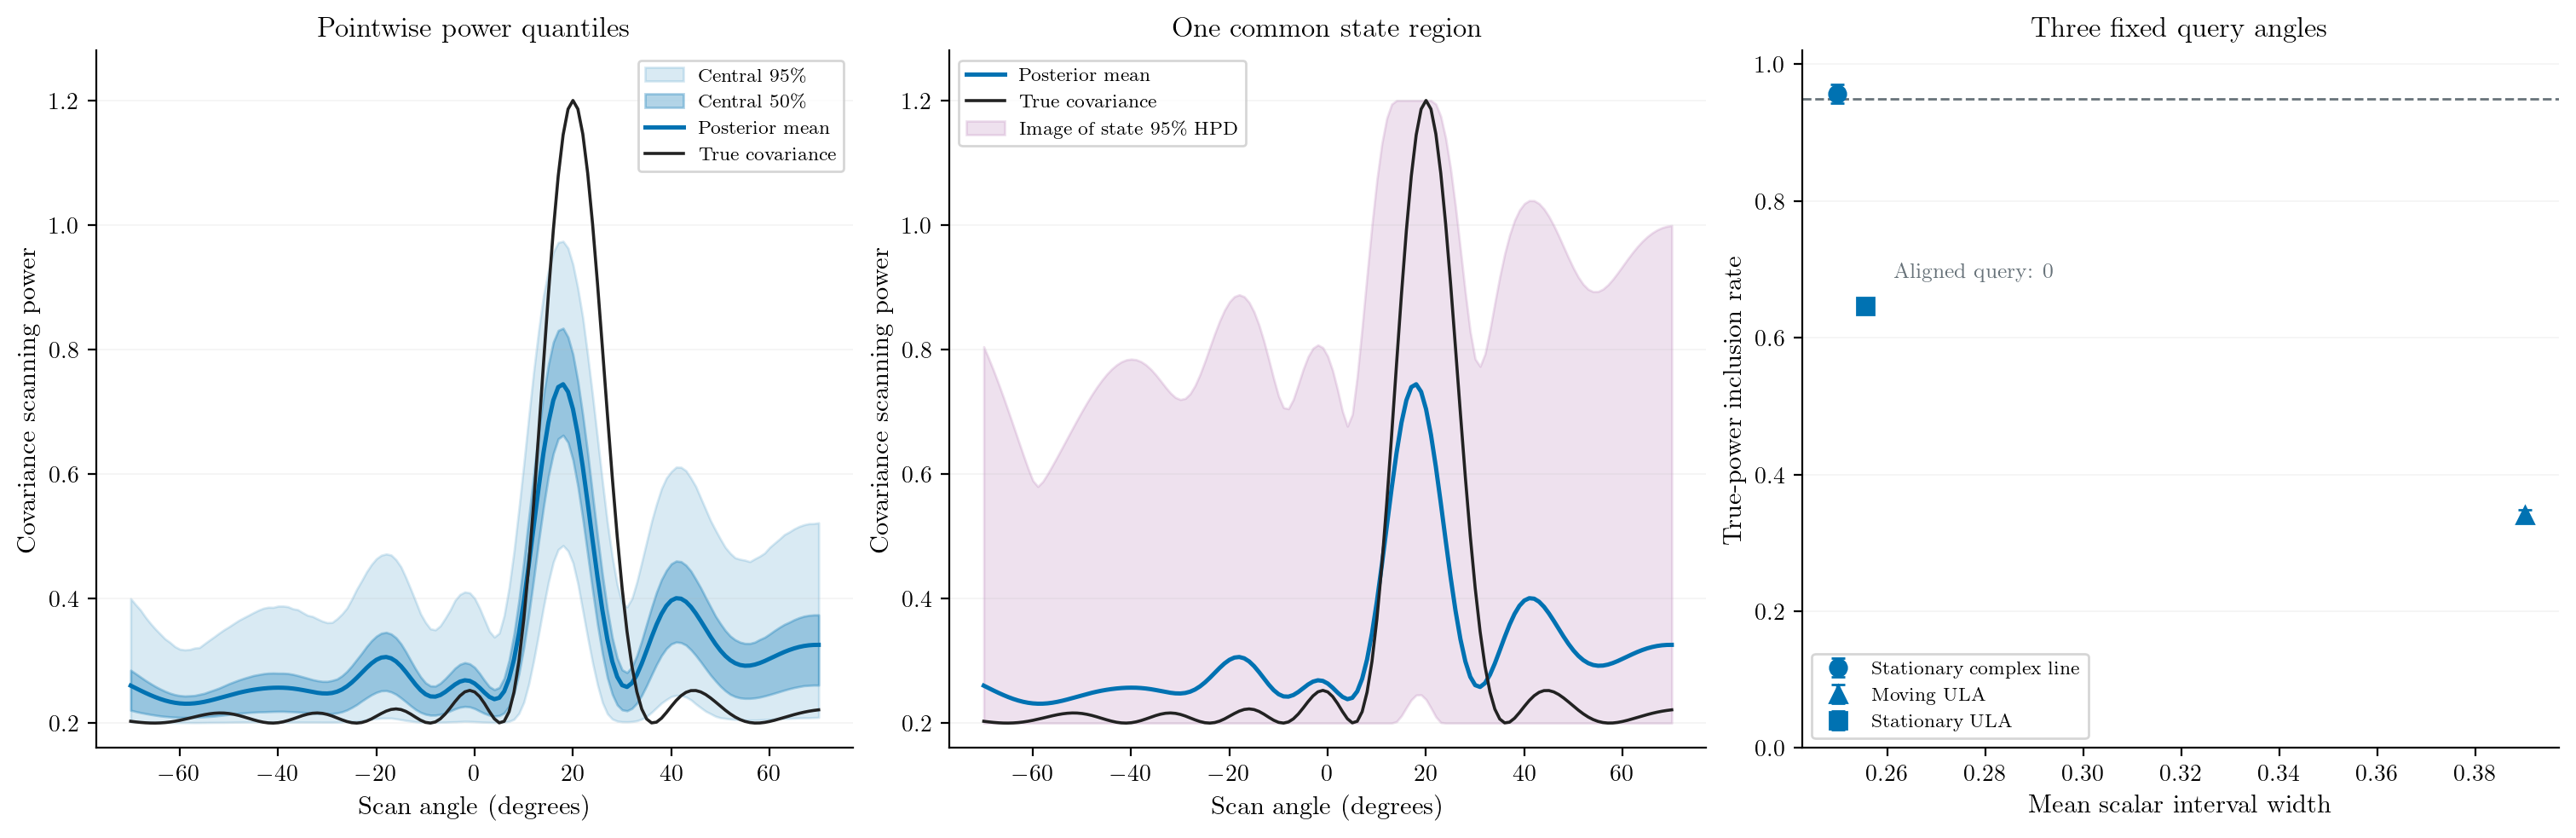

The preassigned stationary-ULA record at N=8 shows scalar central 50/95% power quantiles and, separately, the image of one common 95% state HPD region. The scalar inclusion experiment uses three fixed angular queries, averaged within each trajectory before uncertainty across independent trajectories. At an exact interferer query the truth s+q is a support endpoint and finite continuous-posterior equal-tail intervals exclude it. These fixed-state checks are distinct from prior-predictive Bayesian calibration.

In [6]:
show('05_uncertainty')

## 6. What does uncertainty predict about spatial-projection error?

Here $Pv$ is a **derived posterior query**, not an observed known-input training experiment. For a unit query $v$, $\mathbb E[\|Pv-b\|^2\mid U]=v^H(M-M^2)v+\|Mv-b\|^2$. The mean response $Mv$ minimizes this squared loss. Only its total squared risk is determined by $M$; the full vector covariance needs second moments.

The first panel projects posterior responses onto two real coordinates, $\operatorname{Re}(e_2^HPv)$ and $\operatorname{Im}(e_2^HPv)$. This display is not a full-state credible region. The second shows directional risk from the same saved mean. The last compares predicted risk and actual squared response loss across independent trajectories. Independent queries are averaged within a trajectory before binning, so posterior draws and steering-grid points do not inflate the number of experimental repeats. Perfect fixed-state or misspecified calibration is not assumed.

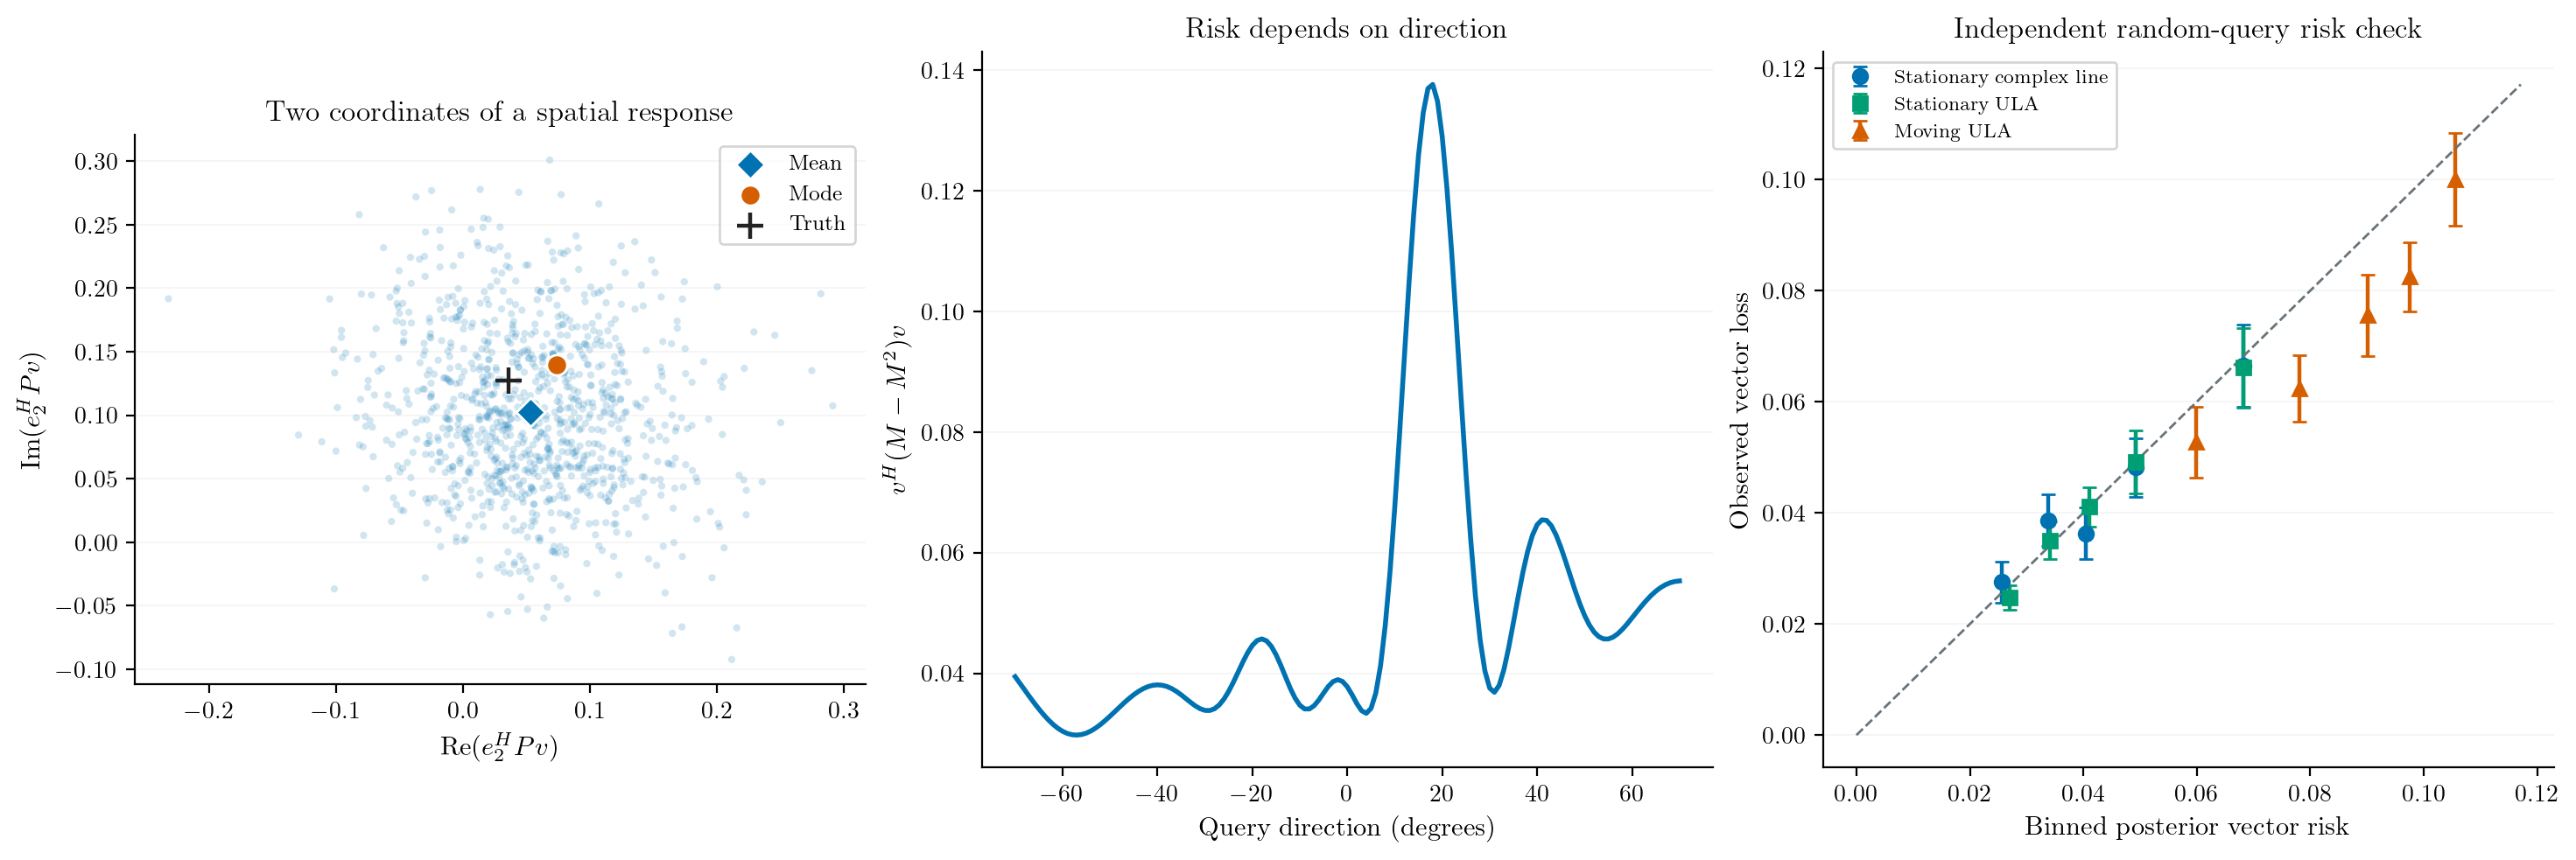

The cloud is only the two-coordinate projection Re/Im(e2^H P v), not a full-state credible region. The directional risk curve is derived from the same saved posterior mean M using v^H(M-M^2)v; these queries are not known training inputs. Binned risk checks use independent random-query trajectories, averaging queries within each trajectory, with pointwise Student intervals across independent trajectories.

For this derived spatial-response loss, the full mean has 25 paired gains and 1 losses in 42 cells against matched isotropization. Directional structure therefore has task-dependent value. These functional prediction comparisons are separate from beamforming-power gains; the cellwise intervals have no multiple-comparison guarantee.

In [7]:
show('06_prediction_and_risk')
paired = D['decisions']['paired']
response = paired[paired.endpoint.eq('projection_loss') & paired.reference.eq('isotropic')]
wins = int((response.low > 0).sum())
losses = int((response.high < 0).sum())
display(Markdown(f"For this derived spatial-response loss, the full mean has {wins} paired "
                 f"gains and {losses} losses in {len(response)} cells against matched isotropization. "
                 "Directional structure therefore has task-dependent value. These functional "
                 "prediction comparisons are separate from beamforming-power gains; "
                 "the cellwise intervals have no multiple-comparison guarantee."))

## 7. What changes when powers are unknown?

The hierarchy uses covariance eigenvalues $a=s+q>b=s>0$ with a proper ordered inverse-gamma prior. Proper complex data contribute shape increments $T$ and $(n-1)T$, without halving the energies. A stationary dataset has **one common projector**. For the moving model, $\kappa$ controls alignment of successive lines through a transition proportional to $\exp\{\kappa\operatorname{tr}(P_tP_{t-1})\}$. A moving dataset has a full path, two neighboring transition terms at interior states and $T-1$ transitions in the concentration likelihood. Integrated state marginals are generally mixtures, not one exact Bingham recursion.

The decision averages the joint covariance $\mathbb E[sI+qP\mid U]$, preserving dependence between powers and state. It does not substitute $\mathbb E[q]\mathbb E[P]$. The preassigned stationary dataset shows joint $(s,q)$ uncertainty and learning across $N$. The independent-cohort panel scores the next snapshot **before assimilation** and separately measures next-covariance output power. Known powers, fixed validation powers and recorded-prior EM are distinct controls. EM ascent applies only to its frozen recorded-prior objective.

This is a bounded parameter-mixing pilot: 64 independent stationary datasets per noise level and smaller moving cohorts, rather than the 256-trajectory decision study. All fits retain strict mixing flags. Scalar means can stabilize while state-tail diagnostics remain unresolved. In particular, the declared moving-chain budget does not establish reliable concentration learning. Hollow/flagged results are diagnostic estimates, not certified joint posterior conclusions. The proper prior sensitivity is retained; no extra sampling was chosen after seeing a favorable decision result.

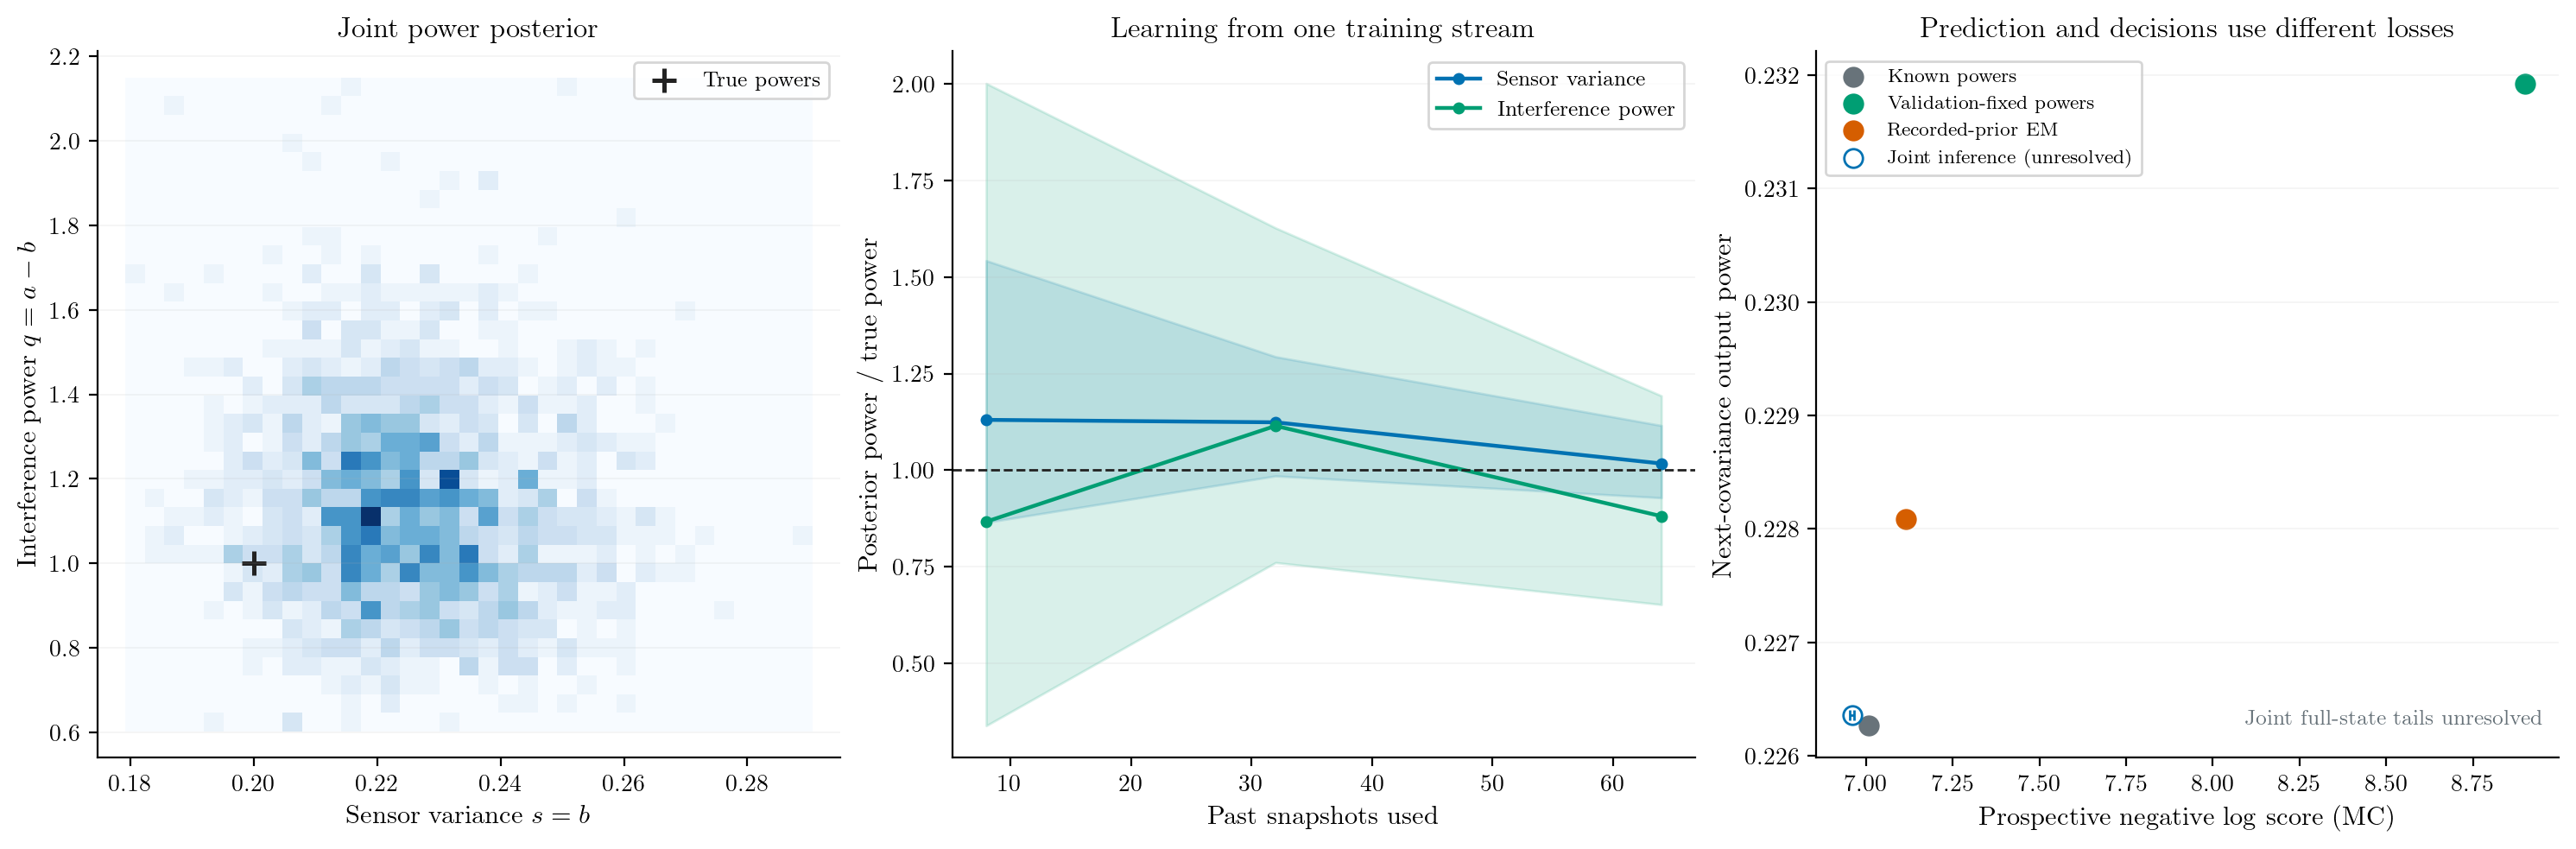

The joint posterior of s=b and q=a-b and data-amount intervals use preassigned stationary trial zero. The last panel averages independent streams at N=32 and scores the next observation and next true covariance before assimilation. Prospective log density and output power are different losses. A filled joint point requires parameter and joint covariance-mean diagnostics; the full-state tail diagnostic is reported separately. Horizontal bars show only 1.96 times the recorded score Monte Carlo standard error of the mean, not variability across data sets or a convergence certificate for the full mixture density.

In [8]:
show('07_parameter_inference')

## 8. What is exact, what is approximate, and what costs time?

For the complex invariant transition, overlap $r=|h_t^Hh_{t-1}|^2$ has density proportional to $e^{\kappa r}(1-r)^{n-2}$. Its exact predictive mean is $\rho_\kappa M+(1-\rho_\kappa)I/n$ when $G=I$. Independent exact transition draws check this law. A single Bingham density fitted to that mean is an approximation to a predictive mixture. A small inverse-moment residual therefore does not establish small density or tail error.

The mean law is exact for the supplied previous distribution. After repeated single-Bingham closures, that previous distribution can already approximate the true filtering posterior. Matching its predictive mean preserves the immediate quadratic-decision and total-risk summaries, but need not preserve regions or later observation updates.

The two-channel ($\mathbb{CP}^1$) reference propagates the full density through an independently refined spherical-harmonic expansion. Targets that fail its positivity or refinement guards remain visibly unresolved. Its density discrepancy is reported separately from the native eight-channel moment residual. It is a low-dimensional reference, not an exact eight-channel density solution. Matched stochastic signatures with $\kappa=4,20$ are separate from deterministic ULA motion, which has no true $\kappa$.

Costs separate correction/eigendecomposition, native means, decisions and posterior reports. The dimension-16 fixture checks feasibility rather than claiming universal scalability. The spectral order cap and exact rejection-sampler proposal cap are finite; hostile high concentrations or repeated top spectra can fail. Failed targets remain recorded instead of receiving an unchecked asymptotic replacement. Native scalar tails use independent 16,384-draw training and 16,384-draw checking batches; finite Monte Carlo uncertainty is not a deterministic tail certificate.

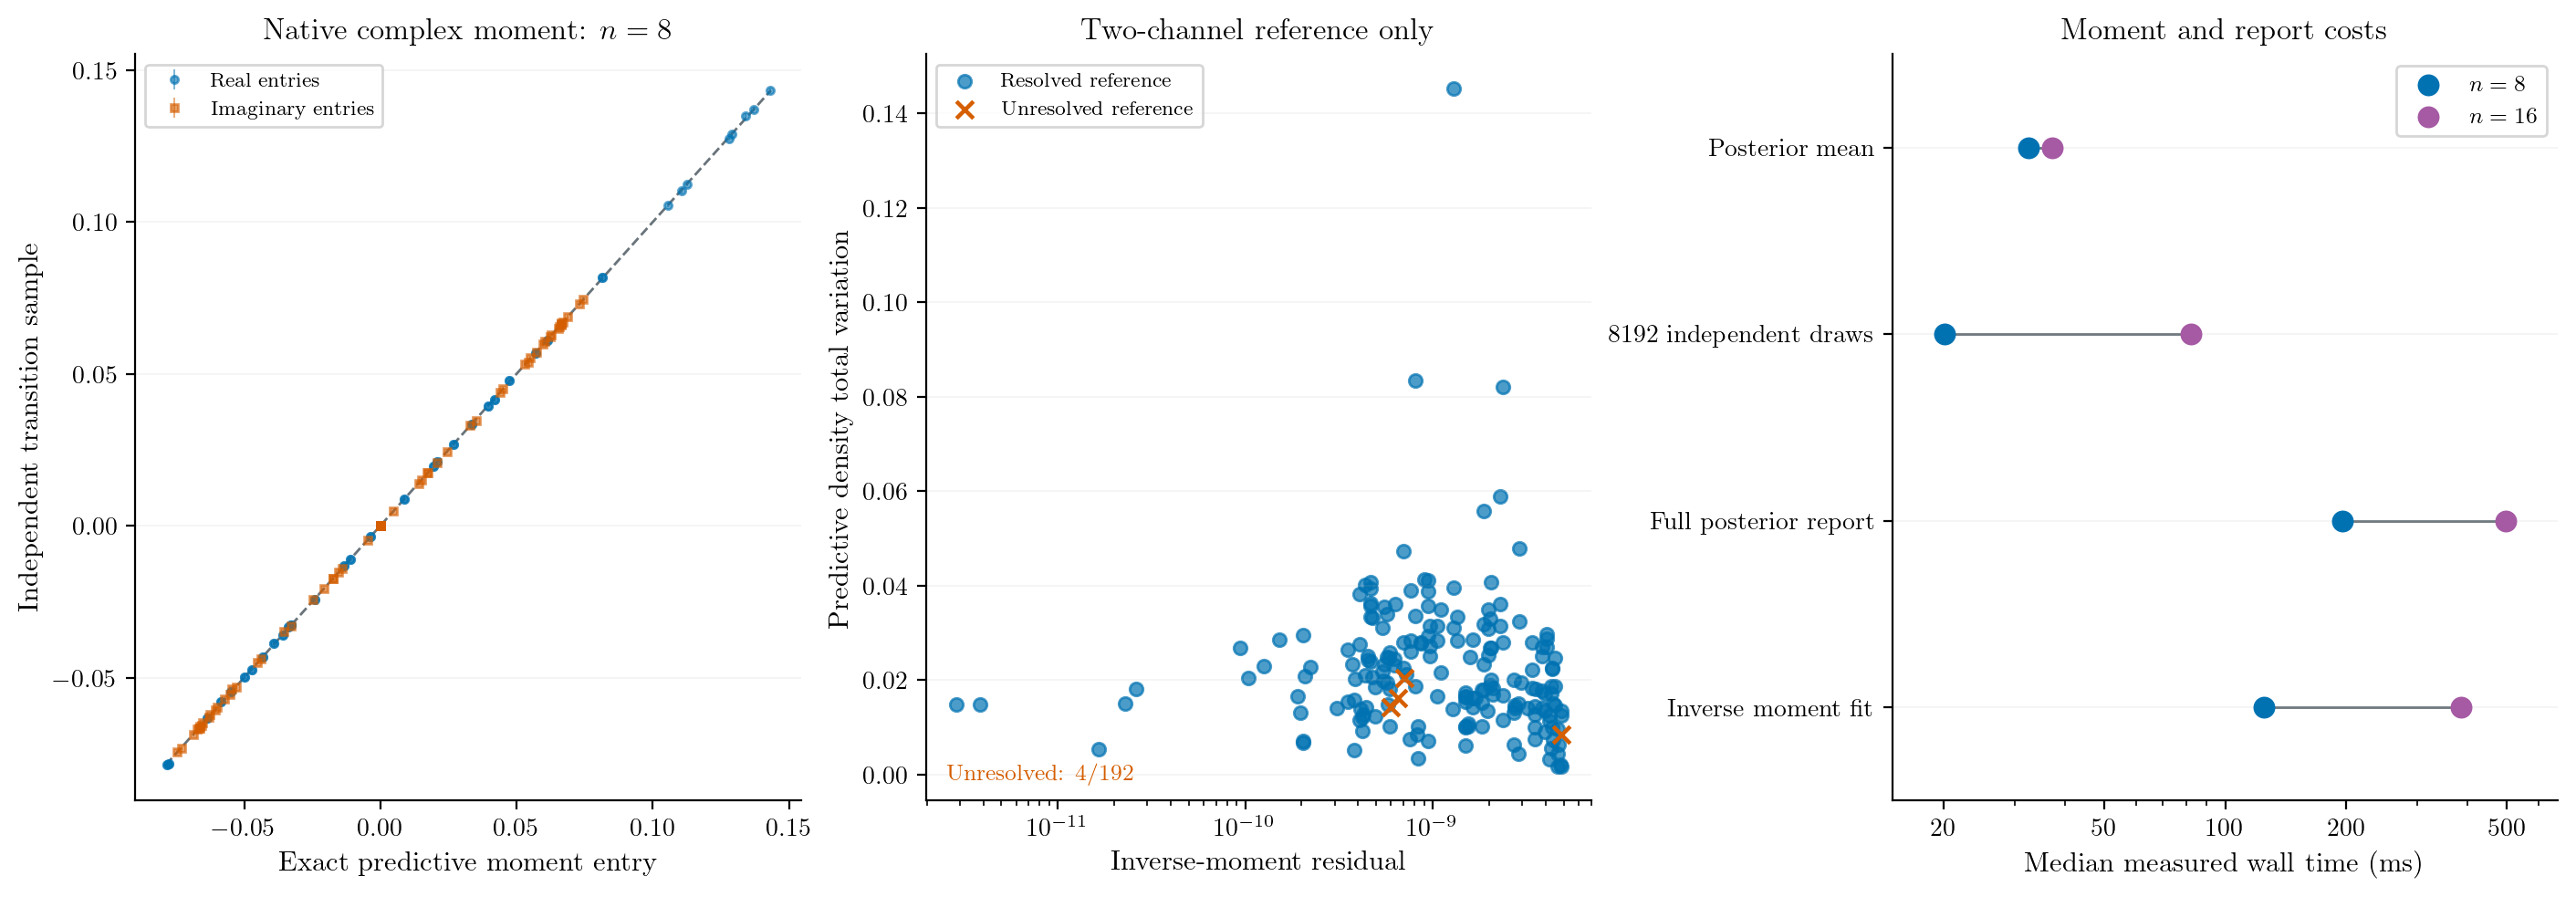

The native eight-sensor complex predictive moment law is checked against independent transition draws, including real and imaginary entries. Exact first-moment matching does not imply exact predictive density: the separate two-channel CP1 reference reports density total variation against inverse-moment residual. Timings cover native numerical operations, not end-to-end comparisons against tracking algorithms. The full report includes its nested sampling and moment work and should not be added to those rows.

For known $\kappa=4$, the paired output-power reduction is 0.0264 (95% interval 0.0196, 0.0332). For known $\kappa=20$, the paired output-power reduction is 0.0236 (95% interval 0.0165, 0.0306). These are matched-process comparisons with fixed $\beta=0.95$ forgetting, not independently tuned competitors. They do not establish successful concentration learning.

In [9]:
show('08_process_and_cost')
pairs = D['process']['paired']
rows = pairs[(pairs.n == 8) & (pairs.t == 24)
             & (pairs.method == 'Process Bingham')
             & (pairs.reference == 'Power forgetting')
             & (pairs.endpoint == 'population_power')]
lines = [f"For known $\\kappa={r.kappa:g}$, the paired output-power reduction is "
         f"{r.gain:.4f} (95% interval {r.lower:.4f}, {r.upper:.4f})."
         for r in rows.itertuples()]
display(Markdown(' '.join(lines) + ' These are matched-process comparisons with '
                'fixed $\\beta=0.95$ forgetting, not independently tuned competitors. '
                'They do not establish successful concentration learning.'))

## Reading the results

The conditional expected-power identity explains **when uncertainty is useful as a decision input**. It does not guarantee a repeated-training win over covariance loading, regularized PCA or a cheap geometric tracker. The complete paired tables are the evidence for those comparisons. One-snapshot equality and the matched isotropization control isolate which apparent benefits arise from regularization and which could arise from directional posterior structure.

A well-justified use of the framework is to obtain a coherent distribution over spatial signatures, derived functional risks and parameter uncertainty when those outputs matter to the application. GROUSE or weighted PCA remain attractive when a point estimate and low computational cost suffice. A general computational or performance superiority claim is unsupported. See [the findings and execution-status table](../results/beamforming_unified/findings.md), [claim map](../docs/beamforming_claims.md) and [proofs and assumptions](../docs/beamforming_theory.md) for precise evidence and limitations.

The matched isotropization control retains a data-dependent amount of regularization; the validation scalar uses one setting shared across independent datasets at each condition and horizon. At one snapshot, posterior concentration scales with the observed energy $\|u\|^2$, so the mean and its isotropization both adapt to that realization even though they are identical. Their comparison separates adaptive spread from directional structure. The stationary physical likelihood is still correct, but the uniform ambient prior does not encode the fixed ULA geometry that validation can exploit. These particular desired/interferer signatures have squared overlap about $0.011$, so strong loading can already produce a good decision. This is one predeclared geometry, not a conclusion about every physical array.

In [10]:
display(Markdown((D['base'].parent / 'main_summary.md').read_text()))

The n=8 passive rank-one paper study has 42 predeclared cells. Posterior-mean true-covariance power comparisons are: mode 42 gains/0 losses; matched isotropization 5 gains/7 losses; regularized PCA 10 gains/28 losses; loaded covariance 13 gains/26 losses; GROUSE 42 gains/0 losses. Gains and losses use paired 95% Student intervals excluding zero; crossing intervals remain inconclusive. These counts provide no multiple-comparison guarantee. One snapshot gives exact mean/isotropization equality, so improvement over the mode there cannot demonstrate anisotropy. The conditional expected-power identity is not a universal empirical advantage. Against regularized PCA, Haar gives 10 gains/0 losses; physical ULA gives 0 gains/28 losses.

Ordinary native means resolve 12/12 targets; 0/1152 evaluated process-tail reports remain unresolved. The known-power certificate is valid in 256/4864 fixed-time reports, with 0 violations. Lowest fixed-state inclusion is HPD, ULA 20 degrees, N=8: 234/256 [0.873, 0.943]. This deviation remains visible. Exact stationary state coverage assumes known powers, a uniform prior, no discounting and exact posterior mass; it does not imply uniform central scalar coverage. Physical-drift HPD inclusion at s=0.2 is 0/32 per policy/time cell, despite resolved numerics. Inferred-kappa checks remain unresolved in 64/64 fits. Maximum cumulative process prediction: 21.2s/trajectory. Shared-host CPU/wall timings reflect contention, not dedicated latency or a complexity law. GROUSE suits cheap point estimates; posterior decisions and uncertainty justify extra work when their assumptions hold and those outputs matter.


# Supplementary comparisons

The following panels retain the other generation laws and all point comparators. The main stationary physical trajectory was fixed in advance, so it should not stand in for the whole study. Concentration plots for deterministic ULA motion describe a fitted model parameter, not error from a true process concentration.

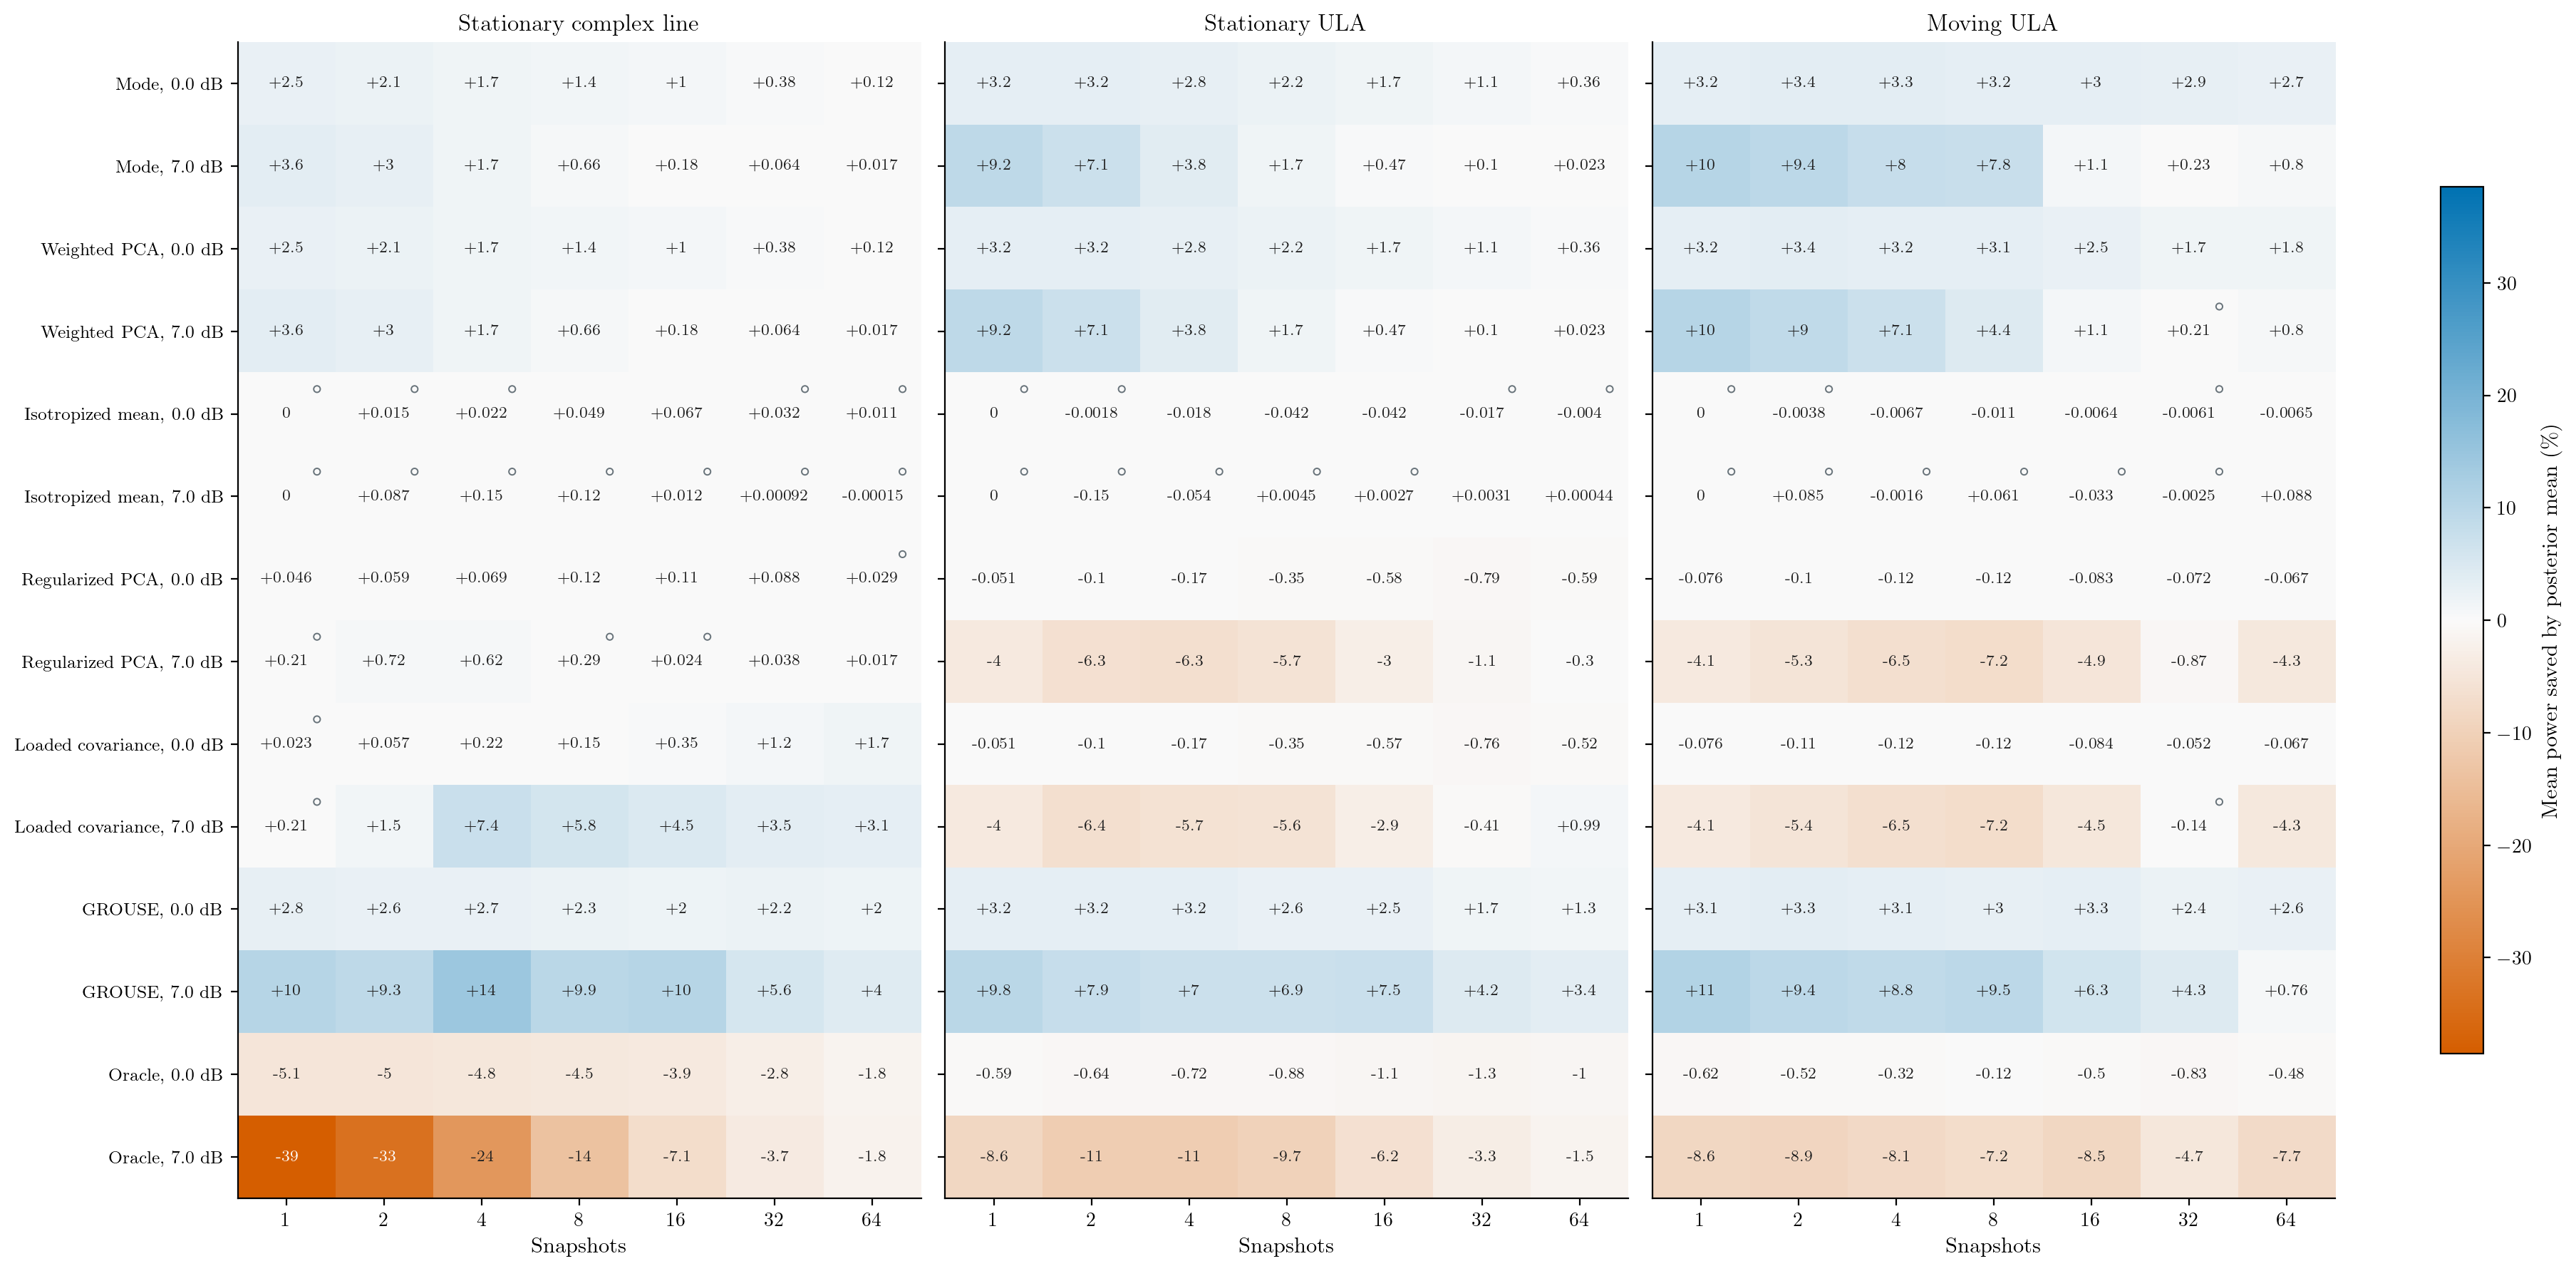

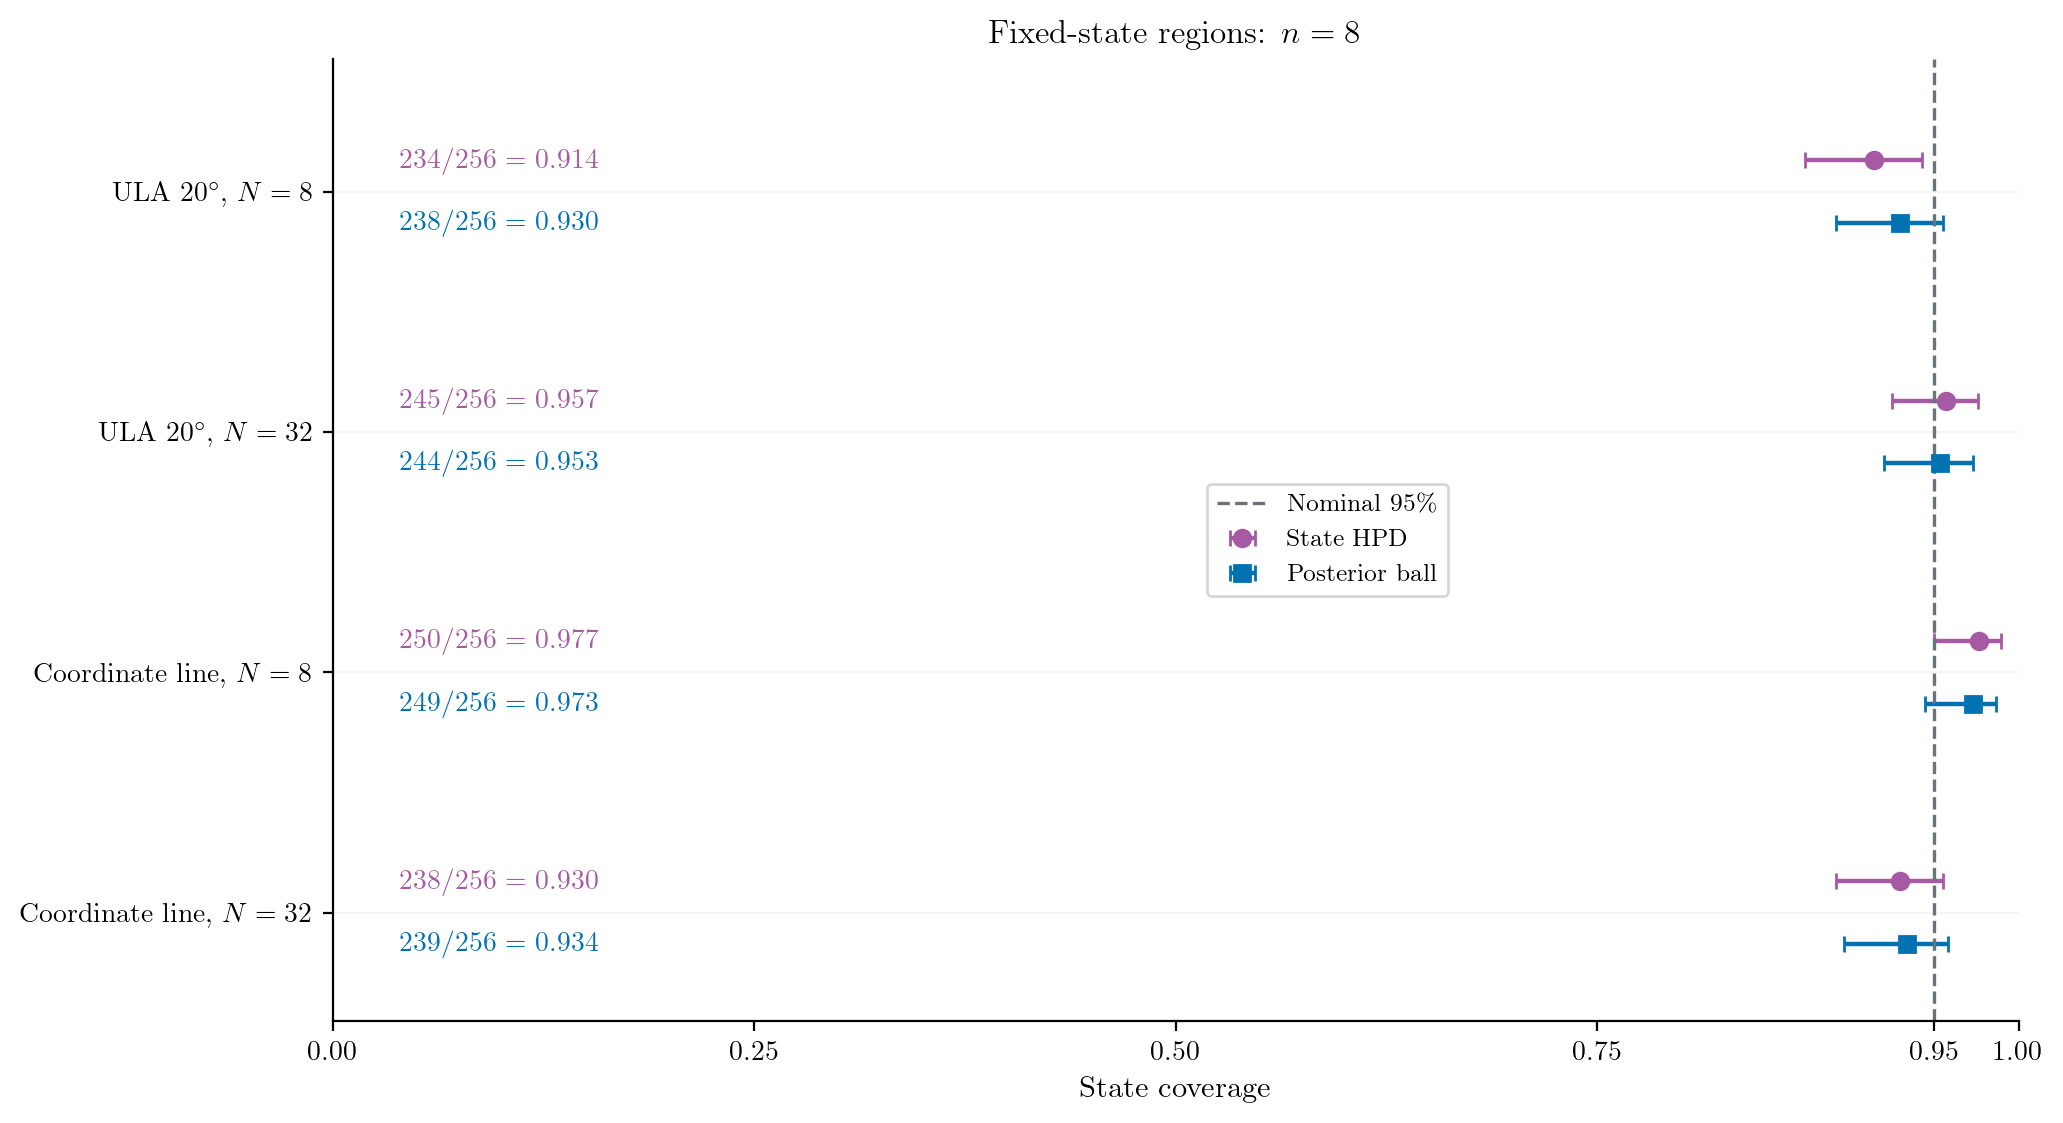

Fixed stationary states, known powers, n=8 and independent observation streams. Markers show the fraction of true states contained in the computed 95% HPD region or posterior ball, with pointwise 95% Wilson binomial intervals. The horizontal scale is the full 0 to 1 coverage range. Eight cells are displayed without a simultaneous or all-cells calibration claim. State-region numerical flags are separate from scalar-tail flags; unresolved state calculations are marked rather than excluded.

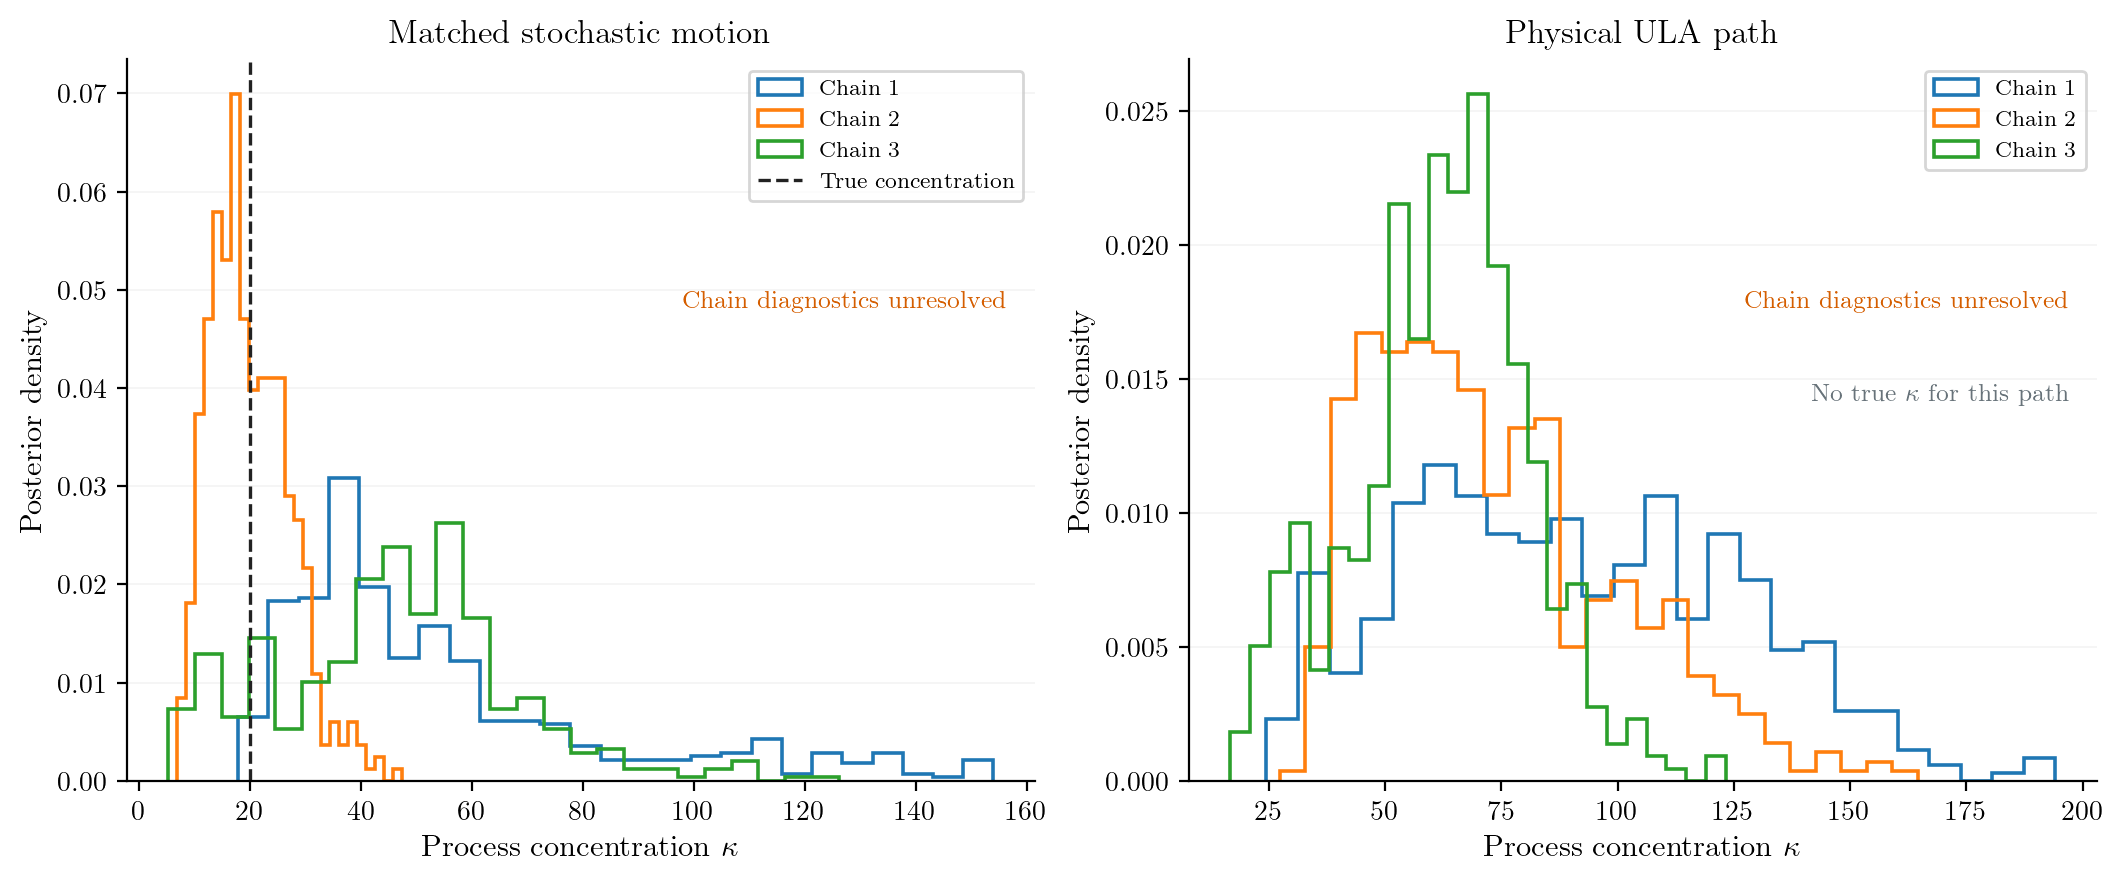

In [11]:
show('04_complete_comparison')
show('05_state_coverage')
show('07_process_parameters')

## Original complex rank-three and real low-data studies

These are **historical results under their original protocols**, preserved byte for byte. Their source snapshots and the original general-validation source tree are independently hash-verified before display. They are not regenerated by the new rank-one protocol. The full original executed notebook is archived [here](../results/beamforming_unified/archive/01_array_base.ipynb).

The first historical figure shows the earlier complex rank-three prediction fans. The second is the separate real three-dimensional low-data comparison; its real model and test/validation counts are not the native complex eight-sensor study. Original convergence caveats, comparisons and tables remain available in the archived notebook. The conditional real known-input Fisher/tracking/balanced-design coverage results retain their own validation in [the general notebook](00_theory.ipynb) and [field example](02_field.ipynb), rather than being relabeled passive-array theorems.

Verified historical certificate and 39 unchanged artifacts.


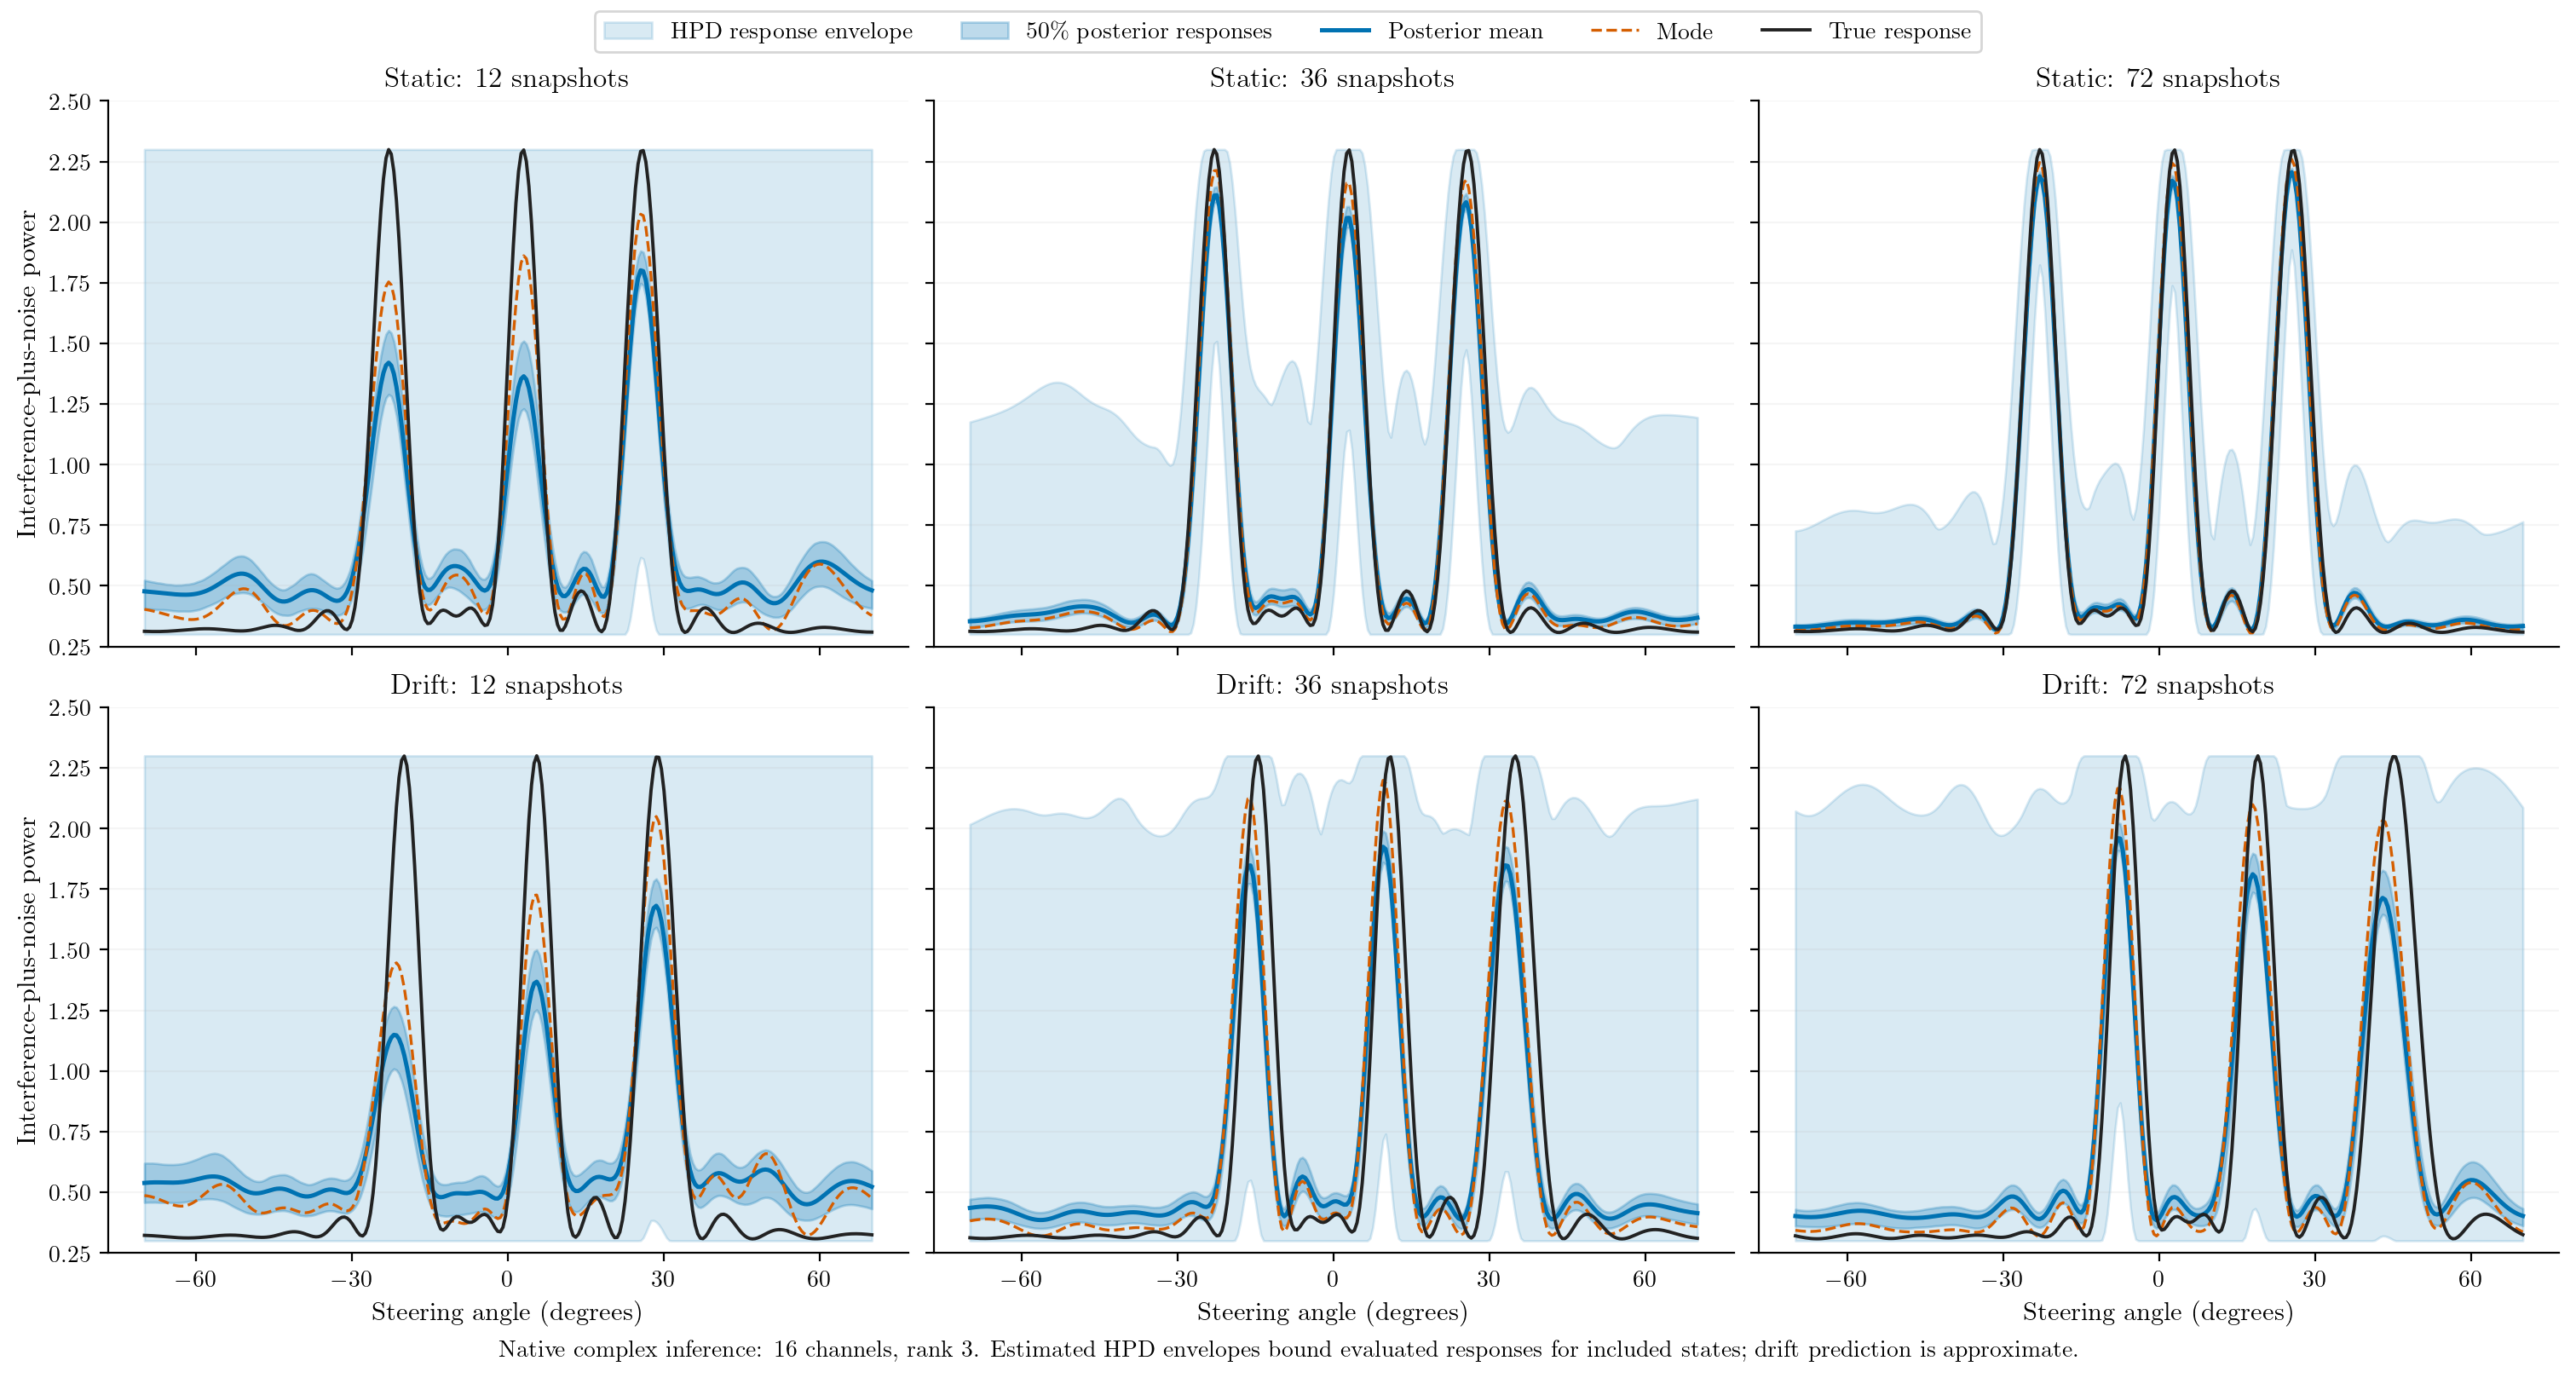

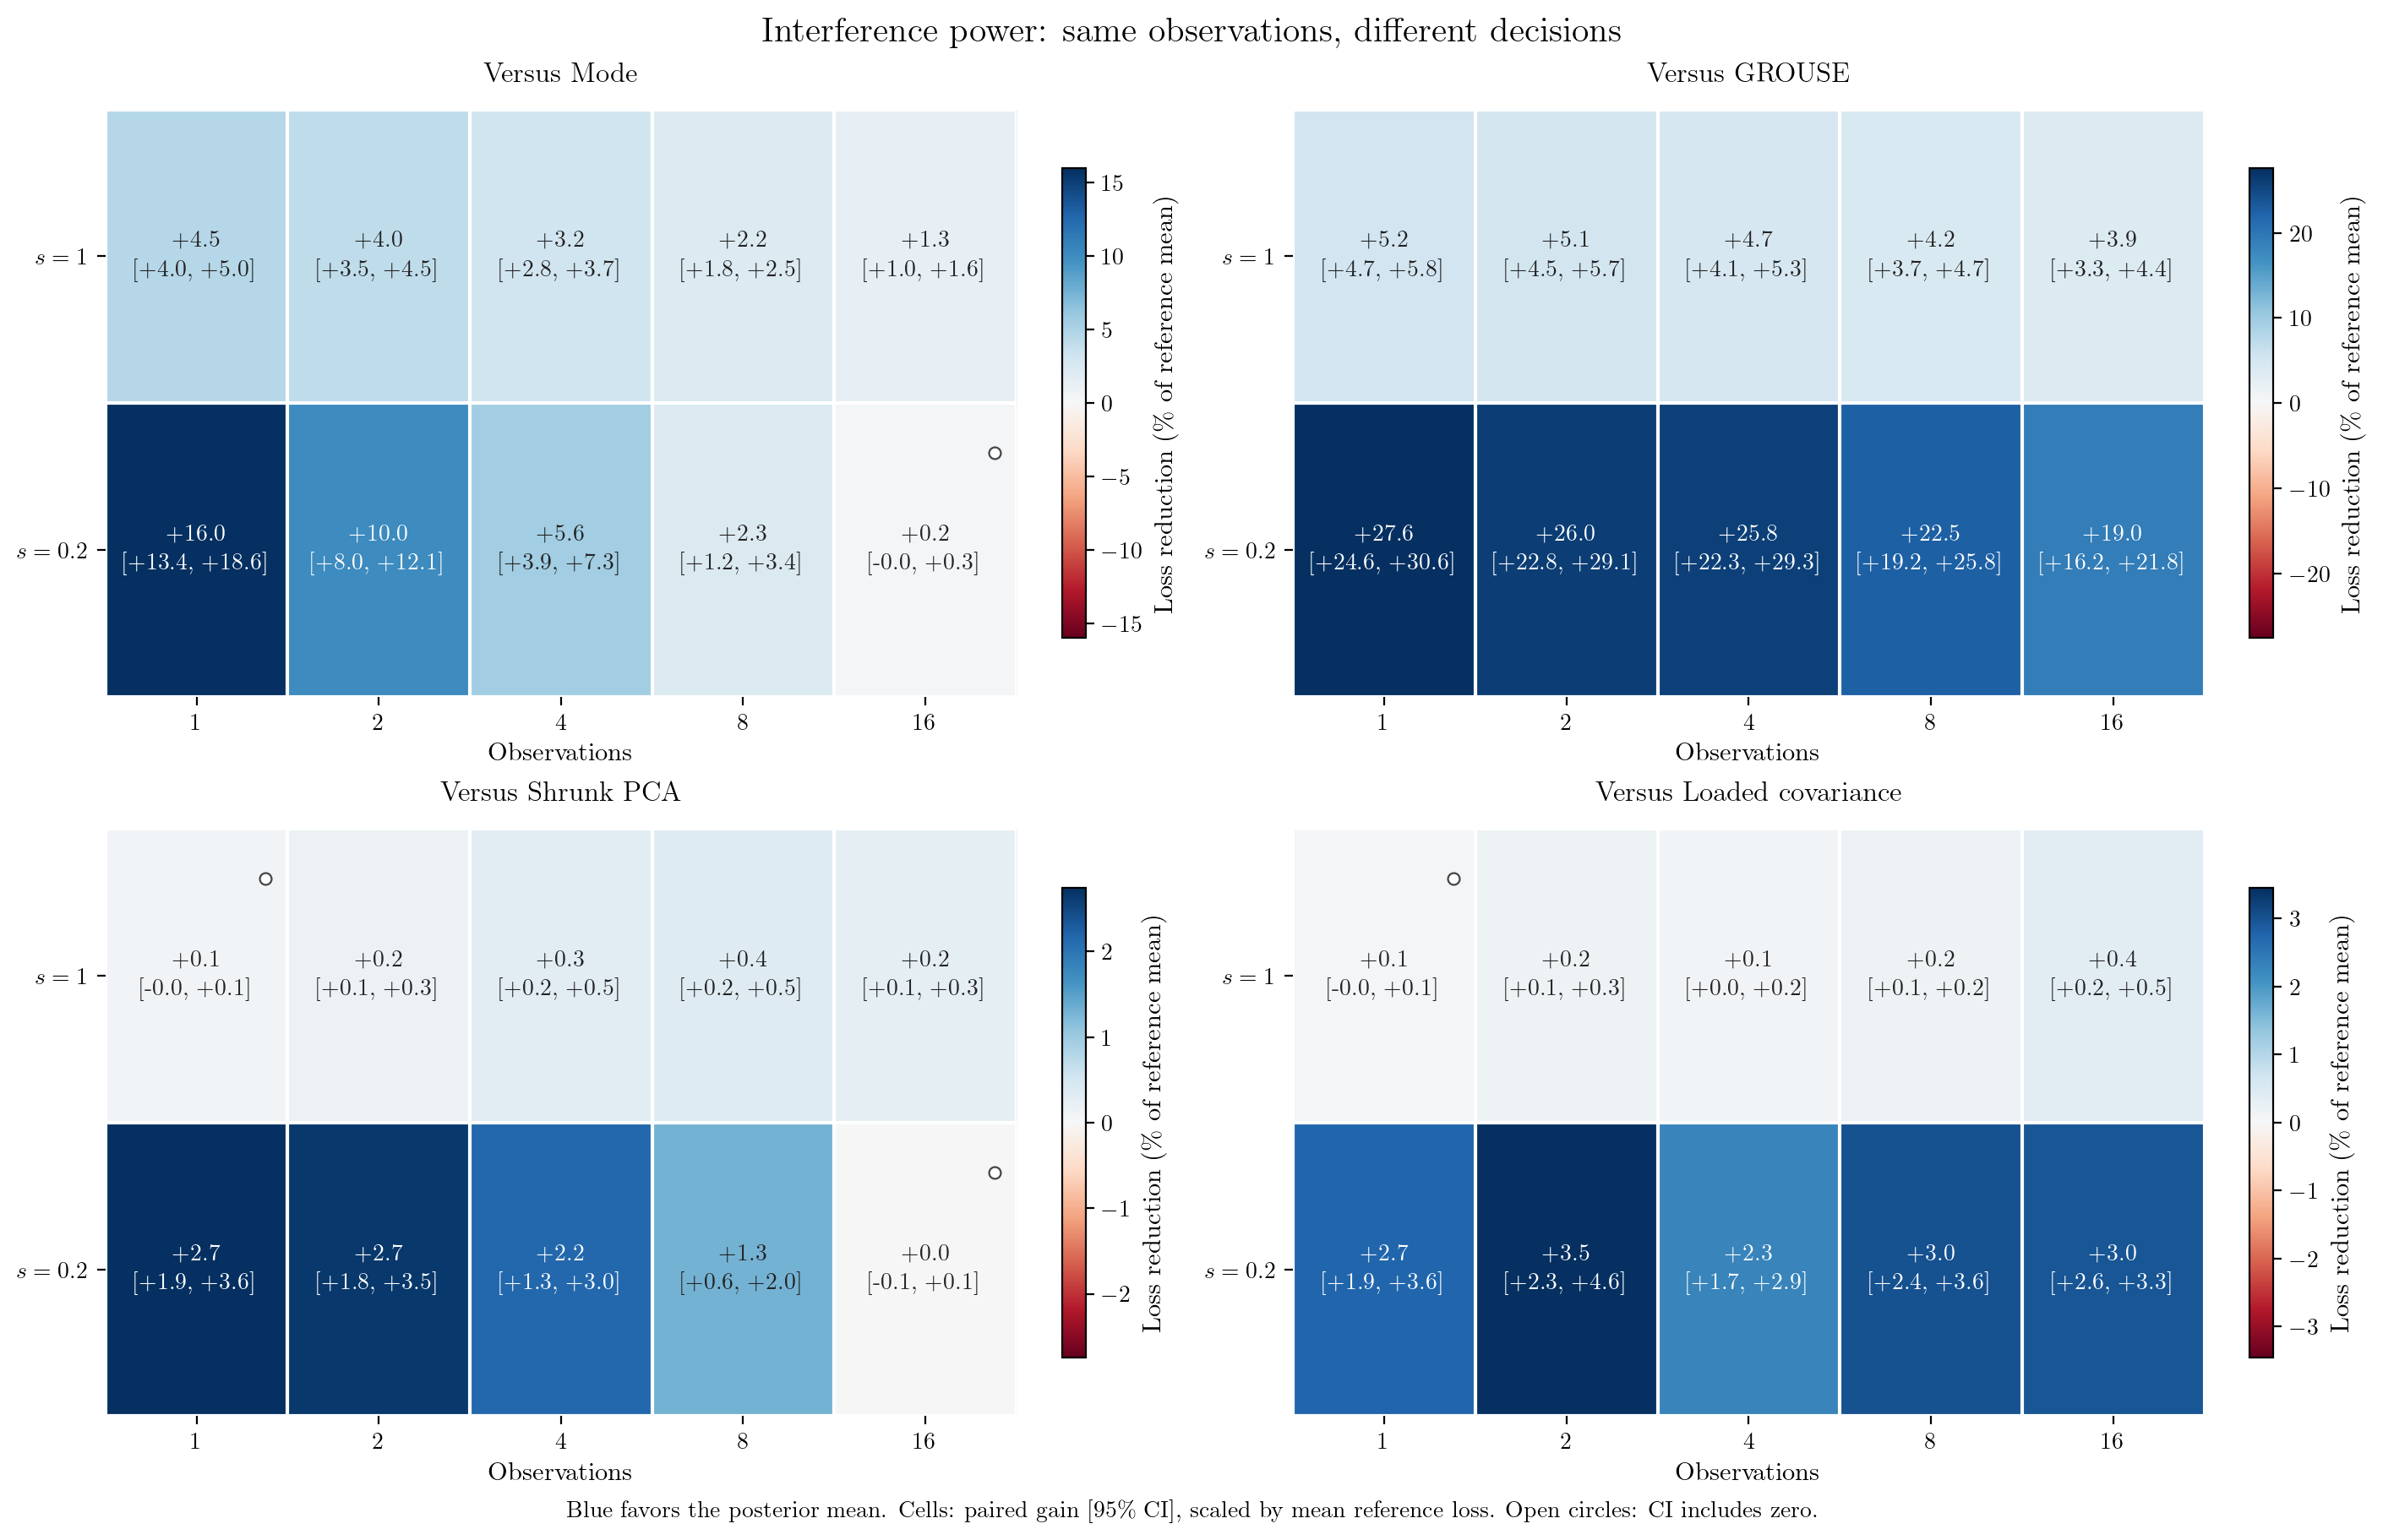

In [12]:
history = verify_historical(ROOT)
print('Verified historical certificate and', len(history['artifacts']), 'unchanged artifacts.')
for name in ('array_prediction_fans.png', 'array_low_data.png'):
    display(Image(filename=str(ROOT / 'results' / name), width=1400))

## Reproducibility

Simulation, figure layout and notebook rendering are separate. All saved tables and figures are content-addressed. Source or configuration changes invalidate the new study; historical results use their archived producer manifests. Quick and paper scientific evaluation streams are disjoint. Full paths and resumable worker checkpoints are excluded from Git where large; their seeds, hashes and exact regeneration commands are recorded in the results README/manifest.

From the repository root, reproduce general validation first, run every component of the selected profile, render its figures, then build and execute this notebook. See [the commands](../results/beamforming_unified/README.md). No manuscript files were edited. The passive derivations cite established Gaussian information, covariance concentration and spectral-projector analysis; the new elements here are their stated specialization and empirical application, not a claim to invent those principles.